# GraphGuard · Phần trình bày của Khánh
## Motif Finding và review IBM · đến Final Task 4 IBM (7/10)

**Sử dụng:** chọn kernel **GraphGuard (.venv Windows)** / `.venv\Scripts\python.exe`, chọn **Restart Kernel → Run All**, rồi trình bày từ trên xuống. Code thuật toán, giải thích, bảng, biểu đồ và output thực chạy cùng nằm trong notebook.

**Môi trường:** Windows Python 3.12, JDK 17, requirements của repo; raw IBM và full Parquet PaySim/IBM đã có. Spark dùng `local[4]`, driver heap **8 GiB**, cấu hình đã chạy trên máy này. Chỉ hạ tầng Windows/Spark được import từ module chung. Các hàm thuật toán và review hiện đầy đủ trong code cells, được đối chiếu AST với production ở cuối notebook.

**Đầu ra:** không xuất thêm CSV, ảnh hoặc log vào repo. Runtime/checkpoint Spark tạm nằm ngoài repo và được dọn khi kết thúc. Các bảng/đồ thị được nhúng trong output notebook.

### Lộ trình và đối chiếu đầy đủ 11 đầu việc

| Hạn | Công việc của Khánh theo CSV phân công | Phần |
|---|---|---|
| 21/9 | Học graph.find + toy cycle 3-node | 1 |
| 25/9 | Review 3.3 của Phương: toán, sink-node, ký hiệu | 2 |
| 28/9 | Final 3.3 | 2 |
| 28/9 | Review IBM ETL của Thảo: schema, 0 dangling, 0 null | 3 |
| 30/9 | Draft Task 3 PaySim: cycle và relay >10.000 | 4 |
| 1/10 | Draft Task 3 IBM | 5 |
| 3/10 | Fix Task 3 PaySim theo tiêu chí review | 4, kiểm tra biên |
| 3/10 | Chạy motif IBM, Code + CSV | 5, đối chiếu CSV bàn giao |
| 5/10 | Review Task 4 IBM của Hoàng | 6 |
| 6/10 | Fix Task 3 IBM theo tiêu chí review | 5, rotations/đa cạnh/currency |
| 7/10 | Final Task 4 IBM | 6–7 |

Các PASS là kiểm chứng tự động, **không thay phê duyệt của Phương/Hoàng/Tuệ Minh**. Nội dung dừng ở mốc 7/10.

## 0 · Môi trường và dữ liệu

Cell sau dừng ngay khi chạy nhầm WSL/kernel, dependency không phù hợp hoặc thiếu dữ liệu full. PaySim dùng full Parquet từ Task 1; IBM ETL được chạy lại từ raw trong bộ nhớ.


In [1]:
from __future__ import annotations
import ast
import csv
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import subprocess
import sys
import tempfile
import time
from datetime import datetime, timezone
from decimal import Decimal
from functools import reduce
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display
from graphframes import GraphFrame
from pyspark.sql import DataFrame, SparkSession, functions as F
from pyspark.sql.functions import col
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, ShortType

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'requirements.txt').is_file() and (p / 'src').is_dir())
NOTEBOOK_PATH = REPO_ROOT / 'notebooks/03_khanh_complete_presentation.ipynb'
assert os.name == 'nt', 'Chọn Windows .venv; không chạy bằng WSL.'
assert sys.version_info[:2] == (3, 12), 'Cần Python 3.12.'
assert os.path.samefile(sys.executable, REPO_ROOT / '.venv/Scripts/python.exe'), 'Chọn .venv của repo.'
sys.path.insert(0, str(REPO_ROOT))
os.environ['PYTHONUTF8'] = '1'
os.environ['PYTHONIOENCODING'] = 'utf-8'
from src.common.spark_session import get_graph_session

for package, expected in [('pyspark','3.5.1'), ('graphframes-py','0.12.2')]:
    assert metadata.version(package) == expected, (package, metadata.version(package))
dependencies = subprocess.run([sys.executable, '-m', 'pip', 'check'], capture_output=True, text=True)
assert dependencies.returncode == 0, dependencies.stdout + dependencies.stderr
print(dependencies.stdout.strip())
for relative in ['data/raw/ibm_aml/HI-Small_Trans.csv', 'data/raw/ibm_aml/HI-Small_accounts.csv',
                 'data/raw/ibm_aml/HI-Small_Patterns.txt',
                 'data/processed/paysim/vertices.parquet', 'data/processed/paysim/edges.parquet',
                 'data/processed/ibm_aml/vertices.parquet', 'data/processed/ibm_aml/edges.parquet',
                 'data/processed/sample/ibm_aml/vertices.parquet']:
    assert (REPO_ROOT / relative).exists(), f'Thiếu dữ liệu: {relative}'
started_at = datetime.now(timezone.utc)
started_clock = time.perf_counter()
checks_passed = {}
plt.rcParams.update({'figure.dpi':110, 'font.family':'DejaVu Sans', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Windows:', platform.platform())
print('Python:', sys.version.split()[0], '|', sys.executable)
print('Bắt đầu UTC:', started_at.isoformat())


No broken requirements found.
Windows: Windows-11-10.0.26300-SP0
Python: 3.12.10 | D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\.venv\Scripts\python.exe
Bắt đầu UTC: 2026-10-18T13:00:28.133395+00:00


Dữ liệu đi qua notebook: **raw IBM → review ETL → GraphFrame → motif/LPA → kiểm tra độc lập → hình và bảng**. Thảo phụ trách ETL, Hoàng phụ trách LPA; Khánh review và kiểm chứng các phần đó.


In [2]:
# Hàm vẽ dùng chung: mũi tên là chiều giao dịch, nhãn cạnh ghi type/time/currency.
# Không savefig(): hình chỉ nhúng vào output notebook.
def draw_graph(nodes, edges, title, positions=None, colors=None):
    if positions is None:
        angles = np.linspace(np.pi/2, np.pi/2 - 2*np.pi, len(nodes), endpoint=False)
        positions = {node:(np.cos(a),np.sin(a)) for node,a in zip(nodes,angles)}
    colors = colors or ['#2563eb']*len(edges)
    fig,ax = plt.subplots(figsize=(10,5))
    for i,(source,target,label) in enumerate(edges):
        start,end = np.array(positions[source]),np.array(positions[target])
        ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=19,
            shrinkA=35,shrinkB=35,color=colors[i%len(colors)],linewidth=2,
            connectionstyle='arc3,rad=0.08'))
        ax.text(*((start+end)/2),label,ha='center',va='center',fontsize=9,
            bbox=dict(facecolor='white',edgecolor='none',alpha=0.95))
    for node,label in nodes.items():
        ax.text(*positions[node],label,ha='center',va='center',color='#0f172a',
            bbox=dict(boxstyle='round,pad=0.7',facecolor='#eff6ff',edgecolor='#93c5fd'))
    ax.set(xlim=(-1.6,1.6),ylim=(-1.4,1.5),title=title)
    ax.axis('off')
    plt.show()

runtime_temp = tempfile.TemporaryDirectory(prefix='graphguard-khanh-',ignore_cleanup_errors=True)
spark = get_graph_session('GraphGuard-Khanh-Presentation',driver_memory='8g',shuffle_partitions=8,
    extra_configs={'spark.master':'local[4]','spark.default.parallelism':'4',
                   'spark.ui.enabled':'false','spark.ui.showConsoleProgress':'false',
                   'spark.sql.warehouse.dir':(Path(runtime_temp.name)/'warehouse').as_uri()})
spark.sparkContext.setLogLevel('ERROR')
java_version = spark.sparkContext._jvm.java.lang.System.getProperty('java.version')
assert java_version.startswith('17.'), java_version
runtime = {'system':platform.system(),'python':platform.python_version(),'spark':spark.version,
    'graphframes':metadata.version('graphframes-py'),'java':java_version,
    'master':spark.sparkContext.master,'driver_memory':spark.sparkContext.getConf().get('spark.driver.memory'),
    'session_timezone':spark.conf.get('spark.sql.session.timeZone')}
display(pd.DataFrame([runtime]))
checks_passed['Windows Python 3.12 / JDK 17 / dependencies'] = True


,system,python,spark,graphframes,java,master,driver_memory,session_timezone
0,Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],8g,Asia/Saigon


In [3]:
# Đọc đủ vertices/edges Parquet rồi tạo GraphFrame.
# Production: src/common/graph_utils.py

def load_graph(spark: SparkSession, data_dir: str) -> GraphFrame:
    """Load GraphFrame từ thư mục chứa vertices.parquet và edges.parquet."""
    data_path = Path(data_dir)
    vertices_path = data_path / "vertices.parquet"
    edges_path = data_path / "edges.parquet"

    if not vertices_path.exists():
        raise FileNotFoundError(f"Không tìm thấy vertices tại: {vertices_path}")
    if not edges_path.exists():
        raise FileNotFoundError(f"Không tìm thấy edges tại: {edges_path}")

    v_df = spark.read.parquet(str(vertices_path))
    e_df = spark.read.parquet(str(edges_path))
    return GraphFrame(v_df, e_df)


## 1 · Toy motif: một cycle, ba phép xoay

Query gán tên cho **đỉnh và cạnh**, tìm mọi cách gán khớp cấu trúc. Ba ID khác nhau loại self-loop và đường đóng chỉ đi qua hai tài khoản. A→B→C→A có ba điểm bắt đầu nên sinh ba dòng. Giữ `a` nhỏ nhất khử phép xoay, giữ nguyên chiều cạnh.


In [4]:
MOTIF_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)"


In [5]:
# Đầy đủ toy graph, truy vấn và kiểm chứng số phép xoay.
# Production: src/motif/toy_cycle.py

def build_toy_graph(spark: SparkSession) -> GraphFrame:
    """Tạo A → B → C → A, mỗi đỉnh và cạnh có thuộc tính để quan sát."""
    vertices = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'Alice'), ('B', 'Bob'), ('C', 'Carol') "
        "AS v(id, name)"
    )
    edges = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'B', 'transfer'), ('B', 'C', 'transfer'), "
        "('C', 'A', 'transfer') "
        "AS e(src, dst, kind)"
    )
    return GraphFrame(vertices, edges)

def find_three_node_cycles(graph: GraphFrame) -> DataFrame:
    """Chạy đúng motif đã giao và loại các đường đóng có đỉnh trùng nhau."""
    return (
        graph.find(MOTIF_PATTERN)
        .where(
            (F.col("a.id") != F.col("b.id"))
            & (F.col("b.id") != F.col("c.id"))
            & (F.col("c.id") != F.col("a.id"))
        )
    )

def cycle_ids(motifs: DataFrame) -> DataFrame:
    """Lấy ID đỉnh theo thứ tự chiều cạnh; mỗi dòng là một phép xoay."""
    return motifs.select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
    )

def run_demo(spark: SparkSession) -> dict:
    """Trả dữ liệu demo và kiểm tra số kết quả mong đợi trên toy graph."""
    graph = build_toy_graph(spark)
    matches = cycle_ids(find_three_node_cycles(graph))
    rows = sorted(tuple(row) for row in matches.collect())
    expected = [("A", "B", "C"), ("B", "C", "A"), ("C", "A", "B")]
    if rows != expected:
        raise AssertionError(f"Motif sai: mong đợi {expected}, nhận {rows}")

    # Chỉ giữ phép xoay bắt đầu ở ID nhỏ nhất, tránh đếm 1 chu trình 3 lần.
    unique = sorted(row for row in rows if row[0] == min(row))
    if unique != [("A", "B", "C")]:
        raise AssertionError(f"Chu trình duy nhất sai: {unique}")

    return {
        "status": "PASS",
        "pattern": MOTIF_PATTERN,
        "vertices": ["A", "B", "C"],
        "edges": [["A", "B"], ["B", "C"], ["C", "A"]],
        "raw_match_count": len(rows),
        "raw_matches": [list(row) for row in rows],
        "unique_cycle_count": len(unique),
        "unique_cycles": [list(row) for row in unique],
    }


,id,name
0,A,Alice
1,B,Bob
2,C,Carol


,src,dst,kind
0,A,B,transfer
1,B,C,transfer
2,C,A,transfer


,a,b,c
0,A,B,C
1,B,C,A
2,C,A,B


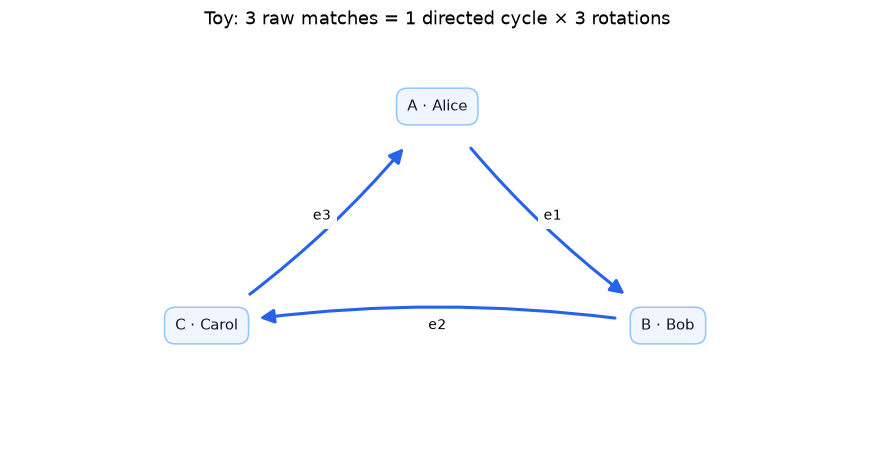

In [6]:
toy = build_toy_graph(spark)
display(toy.vertices.orderBy('id').toPandas())
display(toy.edges.orderBy('src').toPandas())
toy_result = run_demo(spark)
display(pd.DataFrame(toy_result['raw_matches'],columns=['a','b','c']))
assert (toy_result['raw_match_count'],toy_result['unique_cycle_count']) == (3,1)
draw_graph({'A':'A · Alice','B':'B · Bob','C':'C · Carol'},
    [('A','B','e1'),('B','C','e2'),('C','A','e3')],'Toy: 3 raw matches = 1 directed cycle × 3 rotations')
checks_passed['Toy graph.find: 3 rotations / 1 cycle'] = True


## 2 · Review và final PageRank 3.3

### Dẫn xuất qua sáu bước

$A_{vu}$ đếm **số cạnh** từ $v$ tới $u$, $d_{out}(v)=\sum_u A_{vu}$, $N=|V|$, $D$ là tập dangling node. Dùng vector cột, tổng mỗi cột ma trận chuyển bằng 1.

1. **Random walk:** chọn đều một cạnh ra, $\Pr[v\to u]=A_{vu}/d_{out}(v)$.
2. **Transition matrix:** $M_{uv}=A_{vu}/d_{out}(v)$ nếu $d_{out}(v)>0$, ngược lại bằng 0. $r^{(t+1)}=Mr^{(t)}$ là power iteration.
3. **Stationary distribution:** với ma trận stochastic $P$, $r=Pr$, $r\ge0$, $\|r\|_1=1$. Tồn tại chưa đồng nghĩa duy nhất/hội tụ.
4. **Dangling repair:** cột 0 làm mất xác suất (leakage). Với $a_v=1$ khi $v\in D$, đặt $S=M+\frac1N\mathbf e\mathbf a^T$.
5. **Teleportation:** $G=dS+\frac{1-d}{N}\mathbf e\mathbf e^T$, $d=0.85$. $G$ dương và stochastic, có phân phối dừng duy nhất, power iteration hội tụ từ mọi vector xác suất.
6. **Công thức từng đỉnh:**

$$r^{(t+1)}(u)=\frac{1-d}{N}+d\left[\sum_{v:d_{out}(v)>0}\frac{A_{vu}r^{(t)}(v)}{d_{out}(v)}+\frac1N\sum_{v\in D}r^{(t)}(v)\right].$$

### Các điểm review toán, sink và ký hiệu

- Dangling node có out-degree=0 gây **leakage**; rank sink/spider trap là cụm kín gây **trapping**. Hai phần sửa xử lý hai hiện tượng.
- Damping trực tiếp lên $M$ còn cột 0 chưa đủ: cột dangling chỉ cộng thành $1-d$.
- $r(u)\ge(1-d)/N$. Với cụm thực sự $C\subsetneq V$, $\sum_{u\in C}r(u)\le d+(1-d)|C|/N<1$.
- Ánh xạ co có hệ số $d$: $\|r^{(t)}-r^*\|_1\le2d^t$. Chạy 10 vòng chưa chứng minh hội tụ.
- $d$ là xác suất đi theo cấu trúc đã sửa; reset probability = $1-d=0.15$. GraphX có quy ước chuẩn hóa/xử lý dangling riêng; không tự coi output GraphX là đúng vector xác suất minh họa ở đây.
- PageRank đo vị trí trong mạng, **PageRank cao không chứng minh fraud**.

Chuỗi A→B→T với T dangling cho thấy mất mass. Thêm T→T biến T thành absorbing state để quan sát trapping khi $d=1$. Code dưới minh họa toán của review 3.3, không thay module Task 2 của thành viên khác.


,account,d=1,d=0.85
0,A,0.0,0.0500
1,B,0.0,0.0925
2,T,1.0,0.8575


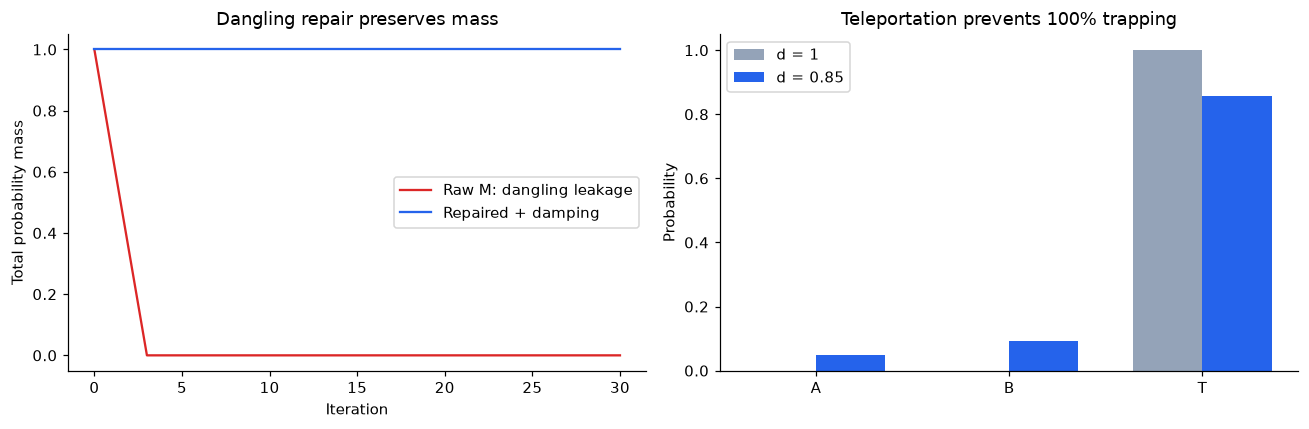

In [7]:
def pagerank_probability(adjacency,damping=0.85,iterations=30,repair_dangling=True):
    # adjacency[v,u] đếm cạnh v→u; chuyển vị để dùng vector cột.
    adjacency = np.asarray(adjacency,dtype=float)
    assert adjacency.ndim == 2 and adjacency.shape[0] == adjacency.shape[1]
    assert (adjacency >= 0).all() and 0 <= damping <= 1
    n = adjacency.shape[0]
    out_degree = adjacency.sum(axis=1)
    transition = np.divide(adjacency,out_degree[:,None],out=np.zeros_like(adjacency),
                           where=out_degree[:,None]>0).T
    if repair_dangling:
        transition[:,out_degree==0] = 1/n
    google = damping*transition + (1-damping)*np.ones((n,n))/n
    rank = np.ones(n)/n
    history = [rank.copy()]
    for _ in range(iterations):
        rank = google @ rank
        history.append(rank.copy())
    return np.asarray(history)

chain = np.array([[0,1,0],[0,0,1],[0,0,0]])
trap = chain.copy()
trap[2,2] = 1
raw_chain = pagerank_probability(chain,1,repair_dangling=False)
fixed_chain = pagerank_probability(chain,0.85)
trapped = pagerank_probability(trap,1)
escapable = pagerank_probability(trap,0.85)
assert np.allclose(raw_chain[:4].sum(axis=1),[1,2/3,1/3,0])
assert np.allclose(fixed_chain.sum(axis=1),1)
assert np.allclose(trapped[-1],[0,0,1])
assert np.allclose(escapable[-1],[0.05,0.0925,0.8575])
display(pd.DataFrame({'account':['A','B','T'],'d=1':trapped[-1],'d=0.85':escapable[-1]}))
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(raw_chain.sum(axis=1),label='Raw M: dangling leakage',color='#dc2626')
axes[0].plot(fixed_chain.sum(axis=1),label='Repaired + damping',color='#2563eb')
axes[0].set(xlabel='Iteration',ylabel='Total probability mass',title='Dangling repair preserves mass')
axes[0].legend()
axes[1].bar(np.arange(3)-0.18,trapped[-1],width=0.36,label='d = 1',color='#94a3b8')
axes[1].bar(np.arange(3)+0.18,escapable[-1],width=0.36,label='d = 0.85',color='#2563eb')
axes[1].set(xticks=np.arange(3),xticklabels=['A','B','T'],ylabel='Probability',
            title='Teleportation prevents 100% trapping')
axes[1].legend()
plt.tight_layout()
plt.show()
checks_passed['PageRank: leakage, damping, mass and worked example'] = True


Nguồn lý thuyết đã dùng trong mục 3.3: Brin & Page (1998), *The Anatomy of a Large-Scale Hypertextual Web Search Engine*; Page et al. (1999), *The PageRank Citation Ranking*; Langville & Meyer (2004), *Deeper Inside PageRank*; Langville & Meyer (2006), *Google’s PageRank and Beyond*. Bản báo cáo: `docs/PartA_Theory.md`.


## 3 · Review IBM ETL của Thảo

| Vấn đề | Cách xử lý trong code đã review |
|---|---|
| Hai cột CSV cùng tên Account | Kiểm tra **toàn bộ header theo thứ tự**, đặt tên nội bộ `Account_Dest` |
| Hai ngân hàng có thể trùng Account | Composite key `bank_id_account`; chuẩn hóa Bank ID Long→String ở cả hai phía |
| Fallback có thể che lỗi khớp account | Kiểm tra riêng **0 fallback**, 0 null/blank tất cả cột, 0 dangling hai phía |
| Tên cột giữa IBM và pipeline | Alias `timestamp/step`, `payment_format/type`, `isLaundering/isFraud`, `currency/payment_currency` |
| Ý nghĩa số liệu | `step` là epoch seconds; `balance=0` là placeholder; `amount` giữ Amount Paid theo tiền gốc |

Hàm ETL được giữ đầy đủ trong các cell tiếp theo. Không gọi phần ghi Parquet: dữ liệu xử lý nằm trong bộ nhớ.


In [8]:
TRANS_HEADER = ['Timestamp','From Bank','Account','To Bank','Account',
                'Amount Received','Receiving Currency','Amount Paid',
                'Payment Currency','Payment Format','Is Laundering']
ACCOUNTS_HEADER = ['Bank Name','Bank ID','Account Number','Entity ID','Entity Name']


In [9]:
# Guard header trước khi đọc CSV; mapping đầy đủ edge và alias contract.
# Production: src/ibm_aml/etl.py

def validate_csv_header(path: str, expected: list[str]) -> None:
    """Validate the ordered raw header before Spark maps duplicate Account columns by position."""
    with open(path, newline="", encoding="utf-8-sig") as stream:
        actual = next(csv.reader(stream), None)
    if actual != expected:
        raise ValueError(
            f"Unexpected CSV header in {path}: expected {expected!r}, got {actual!r}"
        )

def invalid_required_values(df: DataFrame, columns: list[str]) -> dict[str, int]:
    """Count nulls and blank strings in every required output column in one scan."""
    counts = df.agg(*[
        F.sum((F.col(name).isNull() | (F.trim(F.col(name).cast("string")) == "")).cast("long")).alias(name)
        for name in columns
    ]).first()
    return {name: counts[name] or 0 for name in columns}

def build_ibm_edges(spark: SparkSession, trans_csv_path: str) -> DataFrame:
    """Xay dung DataFrame Edges tu HI-Small_Trans.csv"""
    print(f"[*] Dang xu ly Edges tu: {trans_csv_path}")
    validate_csv_header(trans_csv_path, TRANS_HEADER)

    schema = StructType([
        StructField("Timestamp", StringType(), True),
        StructField("From Bank", StringType(), True),
        StructField("Account", StringType(), True),
        StructField("To Bank", StringType(), True),
        # Dat ten khong co dau cham: "Account.1" khien F.col("Account.1") bi
        # Spark hieu nham la truy cap truong long "1" ben trong struct
        # "Account" (dotted nested-field access), gay loi resolve. Doi ten
        # khong anh huong gia tri doc duoc, vi enforceSchema=true (mac dinh)
        # doc CSV theo VI TRI cot, khong theo ten header.
        StructField("Account_Dest", StringType(), True),
        StructField("Amount Received", DoubleType(), True),
        StructField("Receiving Currency", StringType(), True),
        StructField("Amount Paid", DoubleType(), True),
        StructField("Payment Currency", StringType(), True),
        StructField("Payment Format", StringType(), True),
        StructField("Is Laundering", ShortType(), True),
    ])

    raw_trans = spark.read.csv(trans_csv_path, header=True, schema=schema)

    # CHUAN HOA Bank ID: ep qua Long roi tra ve String truoc khi noi chuoi.
    # Ly do: StringType() (fix truoc do) chi dam bao Spark KHONG tu y lam mat
    # so 0 dau -- nhung khong dam bao Trans.csv va accounts.csv dung CHUNG 1
    # kieu dinh dang. Neu Trans.csv ghi "021174" con accounts.csv ghi "21174"
    # cho CUNG 1 ngan hang, composite key se KHONG BAO GIO khop du ca 2 deu
    # la StringType chinh xac. Ep qua Long xoa moi kieu dem so 0 mot cach
    # nhat quan tren ca 2 phia (edges va vertices), dam bao khop dung.
    from_bank_norm = F.col("From Bank").cast("long").cast("string")
    to_bank_norm = F.col("To Bank").cast("long").cast("string")

    edges_df = raw_trans.select(
        F.concat(from_bank_norm, F.lit("_"), F.col("Account")).alias("src"),
        F.concat(to_bank_norm, F.lit("_"), F.col("Account_Dest")).alias("dst"),
        F.col("Amount Paid").alias("amount"),
        # Giu them Amount Received + ca 2 currency de doi chieu/loc theo don
        # vi tien te sau nay -- KHONG duoc so sanh amount qua lai neu currency
        # khac nhau.
        F.col("Amount Received").alias("amount_received"),
        F.col("Payment Currency").alias("payment_currency"),
        F.col("Receiving Currency").alias("receiving_currency"),
        F.col("Payment Currency").alias("currency"),
        # Unix epoch second, KHONG PHAI hour-index nhu PaySim -- xem docstring
        F.unix_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm").cast("integer").alias("step"),
        F.to_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm").alias("timestamp"),
        F.col("Payment Format").alias("type"),
        F.col("Payment Format").alias("payment_format"),
        F.col("Is Laundering").alias("isFraud"),
        F.col("Is Laundering").alias("isLaundering"),
    )

    return edges_df


In [10]:
# Tạo đỉnh Bank–Account, fallback và code sampling đã được review.
# Production: src/ibm_aml/etl.py

def build_ibm_vertices(spark: SparkSession, accounts_csv_path: str, edges_df: DataFrame) -> DataFrame:
    """
    Xay dung DataFrame Vertices tu HI-Small_accounts.csv.
    Ket hop ra soat canh (edges_df) de bo sung cac dinh vang mat (External nodes).
    """
    print(f"[*] Dang xu ly Vertices tu: {accounts_csv_path}")
    validate_csv_header(accounts_csv_path, ACCOUNTS_HEADER)

    # Schema tuong minh -- KHONG dung inferSchema=True. Bank ID trong file nay
    # co the co so 0 dau (vd "012", xem HI-Small_Patterns.txt: From Bank =
    # "021174", To Bank = "012"). Neu de Spark tu suy kieu, cot toan chu so
    # se bi doan thanh kieu so va MAT so 0 dau khi cast lai string ("012" ->
    # 12 -> "12"), khien composite key voi edges_df ("012_...") KHONG BAO GIO
    # khop voi vertices_df ("12_..."). Day la bug nghiem trong nhat trong ban
    # goc: no khong lam assert dangling that bai (fallback-vertex logic se
    # am tham tao node "External/Unknown" trung lap) nen se khong bi phat
    # hien qua kiem tra thong thuong.
    accounts_schema = StructType([
        StructField("Bank Name", StringType(), True),
        StructField("Bank ID", StringType(), True),
        StructField("Account Number", StringType(), True),
        StructField("Entity ID", StringType(), True),
        StructField("Entity Name", StringType(), True),
    ])

    raw_acc = spark.read.csv(accounts_csv_path, header=True, schema=accounts_schema)

    # Chuan hoa GIONG HET phia edges (ep Long -> String) de bao dam khop
    # composite key bat ke Trans.csv/accounts.csv dung quy uoc dem so 0 khac
    # nhau cho cung 1 Bank ID.
    bank_id_norm = F.col("Bank ID").cast("long").cast("string")
    bank_id_cast_fail = raw_acc.filter(F.col("Bank ID").cast("long").isNull()).count()
    if bank_id_cast_fail > 0:
        raise ValueError(f"{bank_id_cast_fail} Bank ID trong accounts.csv khong ep duoc sang so")

    explicit_vertices = raw_acc.select(
        F.concat(bank_id_norm, F.lit("_"), F.col("Account Number")).alias("id"),
        bank_id_norm.alias("bank_id"),
        F.trim(F.split(F.col("Entity Name"), "#").getItem(0)).alias("account_type"),
        F.col("Bank Name").alias("bank_name"),
    ).withColumn("balance", F.lit(0.0))  # IBM khong cung cap balance hien tai

    # Xu ly phong thu (Defensive Vertex Generation): chong Dangling Edges
    active_ids = edges_df.select(F.col("src").alias("id")) \
        .union(edges_df.select(F.col("dst").alias("id"))).distinct()

    missing_ids = active_ids.join(explicit_vertices, on="id", how="left_anti")

    fallback_vertices = missing_ids.select(
        F.col("id"),
        F.split(F.col("id"), "_").getItem(0).alias("bank_id"),
        F.lit("External/Unknown").alias("account_type"),
        F.lit(None).cast("string").alias("bank_name"),
        F.lit(0.0).alias("balance"),
    )

    final_vertices = explicit_vertices.unionByName(fallback_vertices).dropDuplicates(["id"])
    return final_vertices

def sample_ibm_edges(edges_df: DataFrame, target_edges: int = 100_000,
                     target_fraud: int = 89, seed: int = 42) -> DataFrame:
    """Lay ~target_edges canh, voi dung target_fraud canh gian lan."""
    fraud_edges = edges_df.filter(F.col("isFraud") == 1)
    benign_edges = edges_df.filter(F.col("isFraud") == 0)
    fraud_count = fraud_edges.count()
    benign_count = benign_edges.count()
    if fraud_count < target_fraud or benign_count == 0:
        raise ValueError("Khong du canh gian lan/hop le de tao IBM AML sample")

    # Fraud duoc chon theo noi dung canh, khong phu thuoc thu tu partition Spark.
    chosen_fraud = fraud_edges.orderBy(
        F.xxhash64(*[F.col(name) for name in edges_df.columns])
    ).limit(target_fraud)
    benign_fraction = min(1.0, max(0.0, (target_edges - target_fraud) / benign_count))
    return benign_edges.sample(False, benign_fraction, seed).unionByName(chosen_fraud)


### Bộ kiểm tra đầy đủ và đối chiếu raw

`left_anti` tìm endpoint không có vertex tương ứng. Ngoài schema/types và null/dangling, kiểm tra cả Bank ID, alias, fallback, cardinality, fraud labels, self-loop, currency và thời gian. `exceptAll` so input raw với Parquet theo cả hai chiều, có giữ bội số giao dịch.


In [11]:
# Kiểm tra ID null, endpoint, dangling hai phía và self-loop.
# Production: src/common/graph_utils.py

def check_integrity(graph: GraphFrame, verbose: bool = True) -> dict:
    """
    Kiểm tra tính toàn vẹn của GraphFrame:
    - Số lượng Đỉnh, Cạnh
    - Kiểm tra Null
    - Kiểm tra Cạnh treo (Dangling Edges) bằng left_anti join (nhanh hơn .subtract()
      -- left_anti chỉ cần 1 shuffled join, .subtract() thường tốn 2 lần full shuffle)
    - Thống kê Self-loops (src == dst) -- quan trọng với IBM AML (591,212 cạnh loại
      này, 11.64% tổng số cạnh, đã xác nhận trong DE_Paysim_IBM_Comparison.md)

    Lưu ý về `dangling_src + dangling_dst`:
      Đây là tổng số "lượt vi phạm", KHÔNG phải số cạnh treo thực tế nếu một cạnh
      thiếu CẢ src và dst cùng lúc (sẽ bị đếm 2 lần). Hiện tại điều này không xảy ra
      trên cả 2 dataset: PaySim đã được xác nhận vét cạn 0 dangling edges (Task
      2.3/2.4), và IBM AML có defensive vertex generation trong etl.py đảm bảo mọi
      id đều có vertex tương ứng. Cố tình không sửa bằng một phép union().distinct()
      tốn thêm 1 shuffle nữa để loại trùng, vì trường hợp cần loại trùng đó về lý
      thuyết không thể xảy ra với ETL hiện tại -- nếu sau này tổng dangling > 0 một
      cách bất thường, kiểm tra riêng dangling_src/dangling_dst thay vì tin vào tổng.

    Lưu ý về hiệu năng (áp dụng cho caller, không phải bug trong hàm này):
      Hàm này gọi khoảng 6-7 lệnh .count() liên tiếp trên graph.vertices/graph.edges.
      Nếu 2 DataFrame này CHƯA được .cache() ở phía gọi hàm, Spark sẽ tính lại toàn
      bộ pipeline phía trên (đọc lại CSV/Parquet, chạy lại ETL) MỖI LẦN .count() -- 
      tốn kém với 5M+ dòng của IBM AML. Khuyến nghị: cache ngay tại nơi tạo ra
      vertices_df/edges_df (giống export_parquet.py và etl.py đã làm), rồi mới gọi
      check_integrity() trên GraphFrame đã cache.
    """
    num_vertices = graph.vertices.count()
    num_edges = graph.edges.count()

    null_vertices = graph.vertices.filter(col("id").isNull()).count()
    null_edges = graph.edges.filter(col("src").isNull() | col("dst").isNull()).count()

    dangling_src = graph.edges.join(
        graph.vertices, graph.edges["src"] == graph.vertices["id"], "left_anti"
    ).count()
    dangling_dst = graph.edges.join(
        graph.vertices, graph.edges["dst"] == graph.vertices["id"], "left_anti"
    ).count()
    total_dangling = dangling_src + dangling_dst  # see docstring caveat above

    # Self-loop check -- expected 0 for PaySim, expected ~591,212 for IBM AML
    self_loops = graph.edges.filter(col("src") == col("dst")).count()

    result = {
        "num_vertices": num_vertices,
        "num_edges": num_edges,
        "null_vertices": null_vertices,
        "null_edges": null_edges,
        "dangling_src": dangling_src,
        "dangling_dst": dangling_dst,
        "dangling_edges": total_dangling,
        "self_loops": self_loops,
    }

    if verbose:
        print("=" * 65)
        print("GRAPHFRAME INTEGRITY REPORT")
        print("=" * 65)
        print(f"  Vertices (|V|):       {num_vertices:,}")
        print(f"  Edges (|E|):          {num_edges:,}")
        print(f"  Null Vertices:        {null_vertices}  {'[PASS]' if null_vertices == 0 else '[FAIL]'}")
        print(f"  Null Edges (src/dst): {null_edges}  {'[PASS]' if null_edges == 0 else '[FAIL]'}")
        print(f"  Dangling Edges:       {total_dangling}  (src-side: {dangling_src}, dst-side: {dangling_dst})"
              f"  {'[PASS]' if total_dangling == 0 else '[FAIL]'}")
        print(f"  Self-loops (src==dst):{self_loops:,}  (PaySim: expect 0, IBM AML: expect > 0, ~591,212)")
        print("=" * 65)

    return result


In [12]:
EXPECTED_VERTEX_COUNT = 518_581
EXPECTED_EDGE_COUNT = 5_078_345
EXPECTED_FRAUD_COUNT = 5_177
EXPECTED_SAMPLE_FRAUD_COUNT = 89
EXPECTED_SELF_LOOPS = 591_212
EXPECTED_CURRENCY_COUNT = 15
EXPECTED_STEP_MIN = 1_661_965_200
EXPECTED_STEP_MAX = 1_663_492_680


In [13]:
# Bộ kiểm tra IBM ETL đầy đủ của repo, chạy trực tiếp trên raw DataFrame.
# Production: tests/test_ibm_aml_etl.py

def run_tests(spark: SparkSession, vertices_df: DataFrame, edges_df: DataFrame, is_sample: bool = False):
    print("\n" + "=" * 65)
    print(f"IBM AML ETL VERIFICATION SUITE {'[SAMPLE MODE]' if is_sample else '[FULL DATASET]'}")
    print("=" * 65)

    test_results = {}

    vertices_df.cache()
    edges_df.cache()

    v_count = vertices_df.count()
    e_count = edges_df.count()

    # -------------------------------------------------------------
    # 1. KIỂM TRA SCHEMA
    # -------------------------------------------------------------
    expected_v_cols = {"id", "bank_id", "account_type", "bank_name", "balance"}
    expected_e_cols = {
        "src", "dst", "amount", "amount_received",
        "payment_currency", "receiving_currency", "currency", "step",
        "timestamp", "type", "payment_format", "isFraud", "isLaundering",
    }

    v_schema_ok = expected_v_cols.issubset(set(vertices_df.columns))
    e_schema_ok = expected_e_cols.issubset(set(edges_df.columns))

    test_results["Vertices Schema Conformance"] = (
        v_schema_ok, f"Columns: {sorted(list(expected_v_cols))}"
    )
    test_results["Edges Schema Conformance"] = (
        e_schema_ok, f"Columns: {sorted(list(expected_e_cols))}"
    )
    expected_types = {
        "bank_id": "string", "timestamp": "timestamp", "currency": "string",
        "payment_format": "string", "isLaundering": "smallint",
    }
    actual_types = dict(vertices_df.dtypes + edges_df.dtypes)
    test_results["IBM Contract Types"] = (
        all(actual_types.get(name) == value for name, value in expected_types.items()),
        str({name: actual_types.get(name) for name in expected_types}),
    )

    # -------------------------------------------------------------
    # 2. KIỂM TRA NULL + TOÀN VẸN THAM CHIẾU (GRAPH INTEGRITY)
    # -------------------------------------------------------------
    graph = GraphFrame(vertices_df, edges_df)
    integrity = check_integrity(graph, verbose=False)

    test_results["No Null Vertex IDs"] = (
        integrity["null_vertices"] == 0, f"{integrity['null_vertices']} nulls"
    )
    test_results["No Null Edge Endpoints"] = (
        integrity["null_edges"] == 0, f"{integrity['null_edges']} nulls"
    )
    test_results["Referential Integrity (0 Dangling, both sides)"] = (
        integrity["dangling_edges"] == 0,
        f"src-side: {integrity['dangling_src']}, dst-side: {integrity['dangling_dst']}"
    )

    null_v_type = vertices_df.filter(F.col("account_type").isNull()).count()
    test_results["No Null Account Types"] = (null_v_type == 0, f"{null_v_type} nulls")

    fallback_count = vertices_df.filter(F.col("account_type") == "External/Unknown").count()
    test_results["No Fallback Vertices (Real Account Match)"] = (
        fallback_count == 0, f"{fallback_count} External/Unknown vertices"
    )

    null_e_amount = edges_df.filter(F.col("amount").isNull()).count()
    test_results["No Null Edge Amount"] = (null_e_amount == 0, f"{null_e_amount} nulls")
    null_v_fields = invalid_required_values(vertices_df, vertices_df.columns)
    null_e_fields = invalid_required_values(edges_df, edges_df.columns)
    test_results["No Null/Blank Fields in All Vertices"] = (
        all(value == 0 for value in null_v_fields.values()), str(null_v_fields)
    )
    test_results["No Null/Blank Fields in All Edges"] = (
        all(value == 0 for value in null_e_fields.values()), str(null_e_fields)
    )
    alias_errors = edges_df.filter(
        (F.col("currency") != F.col("payment_currency")) |
        (F.col("payment_format") != F.col("type")) |
        (F.col("isLaundering") != F.col("isFraud")) |
        (F.col("timestamp").cast("long") != F.col("step"))
    ).count()
    test_results["IBM Contract Aliases Match GraphGuard Fields"] = (
        alias_errors == 0, f"{alias_errors} inconsistent edges"
    )
    bank_id_errors = vertices_df.filter(
        F.split(F.col("id"), "_").getItem(0) != F.col("bank_id")
    ).count()
    test_results["Vertex Bank ID Matches Composite ID"] = (
        bank_id_errors == 0, f"{bank_id_errors} inconsistent vertices"
    )

    # -------------------------------------------------------------
    # 3. KIỂM TRA CHUẨN HÓA BANK ID & KHỚP TÀI KHOẢN (LOGIC MỚI CHUẨN XÁC)
    # -------------------------------------------------------------
    # Kiểm tra 1: Không còn bất kỳ ID nào bị đệm số 0 thừa ở đầu (vd: '001241_...' phải thành '1241_...')
    unnormalized_edges = edges_df.filter(F.col("src").rlike("^0[0-9]+_") | F.col("dst").rlike("^0[0-9]+_")).count()
    unnormalized_vertices = vertices_df.filter(F.col("id").rlike("^0[0-9]+_")).count()
    no_leading_zeros = (unnormalized_edges == 0 and unnormalized_vertices == 0)

    test_results["Bank IDs Cleanly Normalized (No Leading Zeros)"] = (
        no_leading_zeros,
        f"Unnormalized found: {unnormalized_vertices} vertices, {unnormalized_edges} edges"
    )

    # Kiểm tra 2: Chứng minh các ngân hàng vốn có số 0 đầu trong raw CSV (như 1241 vốn là 001241, 701 vốn là 00701)
    # NAY ĐÃ KHỚP THÀNH CÔNG với accounts.csv (không bị đẩy vào External/Unknown)
    sample_banks = ["1241", "701", "1244", "31125"]
    matched_padded_banks = vertices_df.filter(
        (F.split(F.col("id"), "_").getItem(0).isin(sample_banks)) & 
        (F.col("account_type") != "External/Unknown")
    ).count()

    test_results["Formerly-Padded Banks Successfully Matched"] = (
        matched_padded_banks > 0,
        f"Found {matched_padded_banks:,} vertices from banks {sample_banks} correctly resolved to real account_type"
    )

    # -------------------------------------------------------------
    # 4. KIỂM TRA SỐ LƯỢNG VÀ MIỀN GIÁ TRỊ (CARDINALITY & DOMAIN)
    # -------------------------------------------------------------
    if not is_sample:
        # Số cạnh phải tuyệt đối bằng raw CSV
        test_results["Exact Edge Cardinality"] = (
            e_count == EXPECTED_EDGE_COUNT, f"{e_count:,} vs expected {EXPECTED_EDGE_COUNT:,}"
        )

        # Số lượng gian lận
        fraud_count = edges_df.filter(F.col("isFraud") == 1).count()
        test_results["Ground-truth Fraud Count"] = (
            fraud_count == EXPECTED_FRAUD_COUNT, f"{fraud_count:,} vs expected {EXPECTED_FRAUD_COUNT:,}"
        )

        # HI-Small co dung 518,581 tai khoan; fallback duoc kiem tra rieng o tren.
        test_results["Exact Vertex Population"] = (
            v_count == EXPECTED_VERTEX_COUNT,
            f"Total unique vertices: {v_count:,} vs expected {EXPECTED_VERTEX_COUNT:,}"
        )

        # Vòng lặp tự thân
        self_loops = integrity["self_loops"]
        test_results["Self-loop Invariant"] = (
            self_loops == EXPECTED_SELF_LOOPS, f"{self_loops:,} self-loops (expected {EXPECTED_SELF_LOOPS:,})"
        )

        # Số loại tiền tệ
        distinct_curr = edges_df.select("payment_currency").distinct().count()
        test_results["Multi-currency Invariant"] = (
            distinct_curr == EXPECTED_CURRENCY_COUNT, f"{distinct_curr} distinct payment currencies"
        )

        # Dải thời gian epoch
        step_bounds = edges_df.agg(F.min("step").alias("mn"), F.max("step").alias("mx")).collect()[0]
        step_ok = (step_bounds["mn"] == EXPECTED_STEP_MIN and step_bounds["mx"] == EXPECTED_STEP_MAX)
        test_results["Epoch Time Range (step, NOT 1-744)"] = (
            step_ok, f"min={step_bounds['mn']}, max={step_bounds['mx']} "
                     f"(expected {EXPECTED_STEP_MIN}..{EXPECTED_STEP_MAX})"
        )
    else:
        test_results["Sample Size Check"] = (
            e_count > 0 and v_count > 0, f"Sample: {v_count:,} vertices, {e_count:,} edges"
        )
        sample_fraud_count = edges_df.filter(F.col("isFraud") == 1).count()
        test_results["Sample Ground-truth Fraud Count"] = (
            sample_fraud_count == EXPECTED_SAMPLE_FRAUD_COUNT,
            f"{sample_fraud_count:,} vs expected {EXPECTED_SAMPLE_FRAUD_COUNT:,}"
        )

    # -------------------------------------------------------------
    # IN KẾT QUẢ TỔNG HỢP DATA QUALITY REPORT
    # -------------------------------------------------------------
    all_passed = True
    print("\n" + "-" * 65)
    print("DETAILED VERIFICATION RESULTS")
    print("-" * 65)
    for name, (passed, detail) in test_results.items():
        status = "PASS" if passed else "FAIL"
        if not passed:
            all_passed = False
        print(f"  [{status}] {name:<50} : {detail}")
    print("-" * 65)

    if all_passed:
        print("[+] SUCCESS: Tat ca cac bai kiem thu IBM AML deu DAT CHUAN [PASS].")
    else:
        print("[-] FAILED: Co bai kiem tra that bai. Vui long kiem tra lai pipeline.")
        sys.exit(1)


In [14]:
# Chạy lại ETL full từ raw, không ghi đè Parquet/CSV.
raw_ibm_edges = build_ibm_edges(spark,str(REPO_ROOT/'data/raw/ibm_aml/HI-Small_Trans.csv')).cache()
raw_ibm_vertices = build_ibm_vertices(spark,str(REPO_ROOT/'data/raw/ibm_aml/HI-Small_accounts.csv'),
                                      raw_ibm_edges).cache()
run_tests(spark,raw_ibm_vertices,raw_ibm_edges,is_sample=False)
display(raw_ibm_vertices.limit(5).toPandas())
display(raw_ibm_edges.select('src','dst','timestamp','step','amount','payment_currency','isFraud').limit(5).toPandas())
persisted_ibm = load_graph(spark,str(REPO_ROOT/'data/processed/ibm_aml'))
raw_parquet_comparison = []
for label,fresh,saved in [('vertices',raw_ibm_vertices,persisted_ibm.vertices),
                          ('edges',raw_ibm_edges,persisted_ibm.edges)]:
    columns = sorted(fresh.columns)
    missing = fresh.select(columns).exceptAll(saved.select(columns)).limit(1).count()
    extra = saved.select(columns).exceptAll(fresh.select(columns)).limit(1).count()
    assert missing == extra == 0, f'Raw/Parquet mismatch: {label}'
    raw_parquet_comparison.append({'table':label,'raw_minus_parquet':missing,
                                    'parquet_minus_raw':extra,'status':'PASS'})
display(pd.DataFrame(raw_parquet_comparison))
etl_counts = {'vertices':raw_ibm_vertices.count(),'edges':raw_ibm_edges.count()}
raw_ibm_edges.unpersist()
raw_ibm_vertices.unpersist()
spark.catalog.clearCache()
checks_passed['IBM ETL: raw contract, integrity and exact Parquet reconciliation'] = True


[*] Dang xu ly Edges tu: D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\data\raw\ibm_aml\HI-Small_Trans.csv
[*] Dang xu ly Vertices tu: D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\data\raw\ibm_aml\HI-Small_accounts.csv

IBM AML ETL VERIFICATION SUITE [FULL DATASET]

-----------------------------------------------------------------
DETAILED VERIFICATION RESULTS
-----------------------------------------------------------------
  [PASS] Vertices Schema Conformance                        : Columns: ['account_type', 'balance', 'bank_id', 'bank_name', 'id']
  [PASS] Edges Schema Conformance                           : Columns: ['amount', 'amount_received', 'currency', 'dst', 'isFraud', 'isLaundering', 'payment_currency', 'payment_format', 'receiving_currency', 'src', 'step', 'timestamp', 'type']
  [PASS] IBM Contract Types                                 : {'bank_id': 'str

,id,bank_id,account_type,bank_name,balance
0,10057_803AA8E90,10057,Corporation,Japan Bank #13,0.0
1,10057_803B051A0,10057,Sole Proprietorship,Japan Bank #13,0.0
2,10057_803B1AF50,10057,Partnership,Japan Bank #13,0.0
3,10057_803B2E5F0,10057,Partnership,Japan Bank #13,0.0
4,10057_803B711E0,10057,Partnership,Japan Bank #13,0.0


,src,dst,timestamp,step,amount,payment_currency,isFraud
0,10_8000EBD30,10_8000EBD30,2022-09-01 00:20:00,1661966400,3697.34,US Dollar,0
1,3208_8000F4580,1_8000F5340,2022-09-01 00:20:00,1661966400,0.01,US Dollar,0
2,3209_8000F4670,3209_8000F4670,2022-09-01 00:00:00,1661965200,14675.57,US Dollar,0
3,12_8000F5030,12_8000F5030,2022-09-01 00:02:00,1661965320,2806.97,US Dollar,0
4,10_8000F5200,10_8000F5200,2022-09-01 00:06:00,1661965560,36682.97,US Dollar,0


,table,raw_minus_parquet,parquet_minus_raw,status
0,vertices,0,0,PASS
1,edges,0,0,PASS


## 4 · Task 3 PaySim: cycle = 0 và 2-hop relay

**Rule:** A −TRANSFER→ B −CASH_OUT→ C, ba tài khoản khác nhau, **cả hai amount >10.000**, `transfer_step <= cashout_step`, khoảng cách tối đa 24 giờ mô phỏng. Không dùng nhãn fraud để chọn ứng viên.

PaySim chỉ ghi giờ; cặp cùng giờ không xác định thứ tự thật. `strict_time=True` loại các cặp này. 24 giờ là tham số phân tích do nhóm chọn. Relay là **cặp giao dịch ứng viên**, chưa chứng minh cùng một khoản tiền đi qua hai hop.


In [15]:
RELAY_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c)"


In [16]:
# Code production đầy đủ: lọc cạnh, query, amount/time và flatten.
# Production: src/paysim/motif_finding.py

def find_relays(
    graph: GraphFrame, minimum_amount: float, max_gap_hours: int,
    strict_time: bool = False,
) -> DataFrame:
    """Find three-account relays; same-hour order is unknown in PaySim."""
    if not math.isfinite(minimum_amount) or minimum_amount < 0 or max_gap_hours <= 0:
        raise ValueError("finite minimum_amount >= 0 and max_gap_hours > 0 required")
    eligible_edges = graph.edges.where(
        F.col("type").isin("TRANSFER", "CASH_OUT")
        & (F.col("amount") > minimum_amount)
    )
    eligible_graph = GraphFrame(graph.vertices, eligible_edges)
    time_order = (F.col("e1.step") < F.col("e2.step")) if strict_time else (
        F.col("e1.step") <= F.col("e2.step")
    )
    return eligible_graph.find(RELAY_PATTERN).where(
        (F.col("e1.type") == "TRANSFER")
        & (F.col("e2.type") == "CASH_OUT")
        & (F.col("a.id") != F.col("b.id"))
        & (F.col("b.id") != F.col("c.id"))
        & (F.col("a.id") != F.col("c.id"))
        & time_order
        & ((F.col("e2.step") - F.col("e1.step")) <= max_gap_hours)
    )

def relay_rows(matches: DataFrame) -> DataFrame:
    """Flat columns for a CSV of transaction-pair candidates."""
    return matches.select(
        F.col("a.id").alias("source_account"),
        F.col("b.id").alias("middle_account"),
        F.col("c.id").alias("cashout_account"),
        F.col("e1.step").alias("transfer_step"),
        F.col("e2.step").alias("cashout_step"),
        F.col("e1.amount").alias("transfer_amount"),
        F.col("e2.amount").alias("cashout_amount"),
        F.col("e1.isFraud").alias("transfer_isFraud"),
        F.col("e2.isFraud").alias("cashout_isFraud"),
    )


### Kiểm tra biên và cách đếm đa cạnh

Đồ thị nhỏ có hai hướng cycle, đa cạnh và self-loop. Khử phép xoay phải giữ nguyên bội số và phân biệt hướng. Relay thử ngưỡng **đúng 10.000**, thời gian ngược, cùng giờ và đúng biên 24 giờ.


In [17]:
# Khử phép xoay, giữ bội số giao dịch; áp USD threshold trên mọi cạnh mà không dùng nhãn.
# Production: src/ibm_aml/motif_finding.py

def directed_account_cycles(matches: DataFrame) -> DataFrame:
    """Keep one rotation per directed account cycle, retaining edge multiplicity."""
    return matches.where(
        (F.col("a.id") < F.col("b.id")) & (F.col("a.id") < F.col("c.id"))
    ).select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
    ).groupBy("a", "b", "c").agg(
        F.count("*").alias("transaction_combinations")
    )

def find_usd_cycles(graph: GraphFrame, minimum_amount: float) -> DataFrame:
    """Find label-blind cycles with all three payments strictly above a USD threshold."""
    if not math.isfinite(minimum_amount) or minimum_amount < 0:
        raise ValueError("minimum USD amount must be finite and >= 0")
    edges = graph.edges.where(
        (F.col("payment_currency") == "US Dollar")
        & (F.col("amount") > minimum_amount)
    )
    return find_three_node_cycles(GraphFrame(graph.vertices, edges))


In [18]:
# Phản ví dụ có đa cạnh, hai hướng và self-loop.
v_test = spark.sql("SELECT * FROM VALUES ('A'),('B'),('C') AS v(id)")
e_test = spark.sql("SELECT * FROM VALUES ('A','B'),('A','B'),('B','C'),('C','A'),"
                   "('A','C'),('C','B'),('B','A'),('A','A') AS e(src,dst)")
cycle_test = find_three_node_cycles(GraphFrame(v_test,e_test))
assert cycle_test.count() == 9
assert sorted(r.transaction_combinations for r in directed_account_cycles(cycle_test).collect()) == [1,2]
v_boundary = spark.sql("SELECT * FROM VALUES ('A'),('B'),('D'),('E'),('F'),('X') AS v(id)")
e_boundary = spark.sql("SELECT * FROM VALUES "
    "('A','B','TRANSFER',10000.0,10,0),('X','B','TRANSFER',11000.0,10,1),"
    "('B','A','CASH_OUT',10000.0,12,0),('B','D','CASH_OUT',11000.0,10,0),"
    "('B','E','CASH_OUT',11000.0,34,0),('B','F','CASH_OUT',11000.0,35,0),"
    "('B','A','CASH_OUT',11000.0,9,0),('B','X','CASH_OUT',11000.0,12,0) "
    "AS e(src,dst,type,amount,step,isFraud)")
boundary_graph = GraphFrame(v_boundary,e_boundary)
assert sorted(r.id for r in find_relays(boundary_graph,10000,24).select('c.id').collect()) == ['D','E']
assert find_relays(boundary_graph,10000,24,strict_time=True).count() == 1
print('PASS: rotations, parallel edges, direction, self-loop, amount/time boundaries')
checks_passed['Motif adversarial graphs and relay boundaries'] = True


PASS: rotations, parallel edges, direction, self-loop, amount/time boundaries


### Chạy full PaySim và đối chiếu CSV bàn giao

Không kết luận cycle full bằng 0 chỉ từ sample. Cell này tìm trên **9.073.900 đỉnh / 6.362.620 cạnh**, sau đó so từng dòng relay với CSV đã commit.


In [19]:
pay_loaded = load_graph(spark,str(REPO_ROOT/'data/processed/paysim'))
pay = GraphFrame(pay_loaded.vertices.select('id').cache(),pay_loaded.edges.select(
    'src','dst','type','amount','step','isFraud').cache())
pay_v,pay_e = pay.vertices.count(),pay.edges.count()
assert (pay_v,pay_e) == (9_073_900,6_362_620)
pay_cycles = find_three_node_cycles(pay)
pay_cycle_count = pay_cycles.count()
pay_directed_count = pay_cycles.where((F.col('a.id')<F.col('b.id')) &
    (F.col('a.id')<F.col('c.id'))).select('a.id','b.id','c.id').distinct().count()
pay_matches = find_relays(pay,10_000.0,24).cache()
pay_relay_count = pay_matches.count()
pay_same_hour = pay_matches.where(F.col('e1.step')==F.col('e2.step')).count()
pay_relays = relay_rows(pay_matches).orderBy('transfer_step','cashout_step','source_account',
    'middle_account','cashout_account','transfer_amount','cashout_amount').toPandas()
pay_metrics = {'scope':'full','vertices':pay_v,'edges':pay_e,'raw_cycles':pay_cycle_count,
    'directed_cycles':pay_directed_count,'relay_pairs':pay_relay_count,'same_hour':pay_same_hour,
    'strict_later':pay_relay_count-pay_same_hour}
assert (pay_cycle_count,pay_directed_count,pay_relay_count,pay_same_hour) == (0,0,30,2)
baseline = pd.read_csv(REPO_ROOT/'results/paysim/relay_candidates.csv')
keys = list(pay_relays.columns)
pd.testing.assert_frame_equal(pay_relays.sort_values(keys).reset_index(drop=True),
    baseline[keys].sort_values(keys).reset_index(drop=True),check_dtype=False,check_exact=True)
display(pd.DataFrame([pay_metrics]))
display(pay_relays.head(10))
assert (pay_relays[['transfer_isFraud','cashout_isFraud']]==0).all().all()
print('PASS: CSV khớp đủ 30/30; hai cạnh của mọi ứng viên đều có nhãn 0.')
checks_passed['Task 3 PaySim full + exact delivered CSV'] = True


,scope,vertices,edges,raw_cycles,directed_cycles,relay_pairs,same_hour,strict_later
0,full,9073900,6362620,0,0,30,2,28


,source_account,middle_account,cashout_account,transfer_step,cashout_step,transfer_amount,cashout_amount,transfer_isFraud,cashout_isFraud
0,C1933517957,C1939958280,C232785081,24,37,265406.49,400729.53,0,0
1,C831358900,C874023329,C1468339976,34,47,1326914.02,292696.43,0,0
2,C1554009922,C874023329,C1468339976,36,47,149467.61,292696.43,0,0
3,C1739712760,C1360393616,C654237876,44,44,161654.47,75989.57,0,0
4,C1483406592,C2013691076,C1228316980,129,132,255345.27,433722.00,0,0
5,C11465170,C1883483535,C792212230,139,139,456477.88,247241.29,0,0
6,C1076477679,C991247178,C1344561835,143,162,195823.90,60387.69,0,0
7,C532453433,C1708070258,C11164223,155,177,1310843.36,406454.19,0,0
8,C1558625741,C1838628808,C224572740,156,158,213684.91,123530.04,0,0
9,C1766969454,C1708070258,C11164223,156,177,822049.92,406454.19,0,0


PASS: CSV khớp đủ 30/30; hai cạnh của mọi ứng viên đều có nhãn 0.


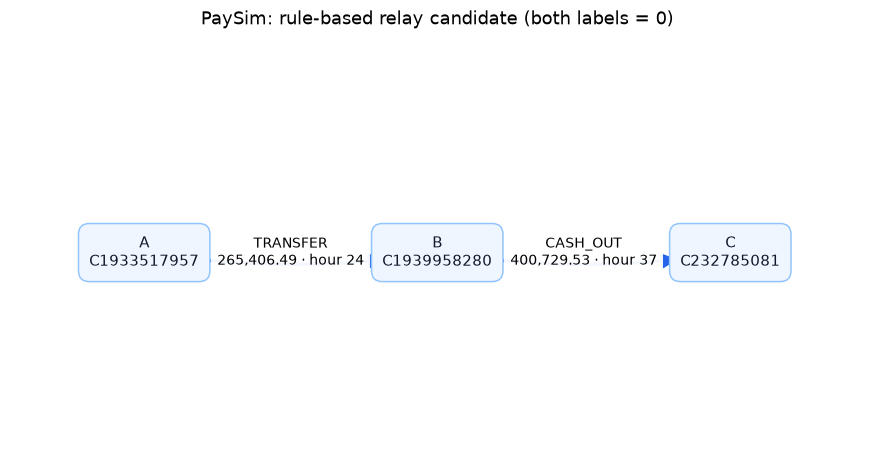

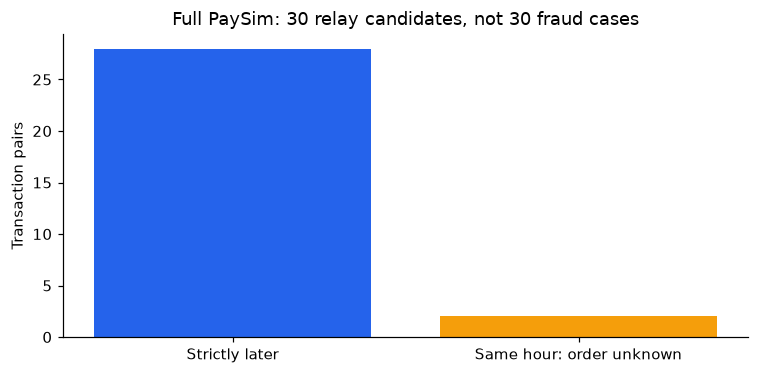

In [20]:
# Chọn ứng viên có thứ tự giờ rõ ràng. Hai amount không cần bằng nhau.
example = pay_relays.loc[pay_relays.cashout_step>pay_relays.transfer_step].iloc[0]
draw_graph({'A':'A\n'+example.source_account,'B':'B\n'+example.middle_account,
            'C':'C\n'+example.cashout_account},
    [('A','B',f'TRANSFER\n{example.transfer_amount:,.2f} · hour {example.transfer_step}'),
     ('B','C',f'CASH_OUT\n{example.cashout_amount:,.2f} · hour {example.cashout_step}')],
    'PaySim: rule-based relay candidate (both labels = 0)',
    positions={'A':(-1.1,0),'B':(0,0),'C':(1.1,0)})
fig,ax = plt.subplots(figsize=(7,3.5))
ax.bar(['Strictly later','Same hour: order unknown'],[pay_relay_count-pay_same_hour,pay_same_hour],
       color=['#2563eb','#f59e0b'])
ax.set(ylabel='Transaction pairs',title='Full PaySim: 30 relay candidates, not 30 fraud cases')
plt.tight_layout()
plt.show()
pay_matches.unpersist()
pay.vertices.unpersist()
pay.edges.unpersist()
spark.catalog.clearCache()


## 5 · Task 3 IBM HI-Small: đếm cycle đúng

| Query | Điều kiện | Ý nghĩa |
|---|---|---|
| Audit nhãn | Ba cạnh thuộc graph `isFraud=1` | Kiểm tra cấu trúc **đã gắn nhãn**, không đánh giá detector |
| USD không dùng nhãn | Mọi cạnh `payment_currency='US Dollar'`, `amount>10.000` | Rule theo tiền có đơn vị thống nhất, không lọc isFraud |

Phân biệt **raw rows**, **bộ ba có thứ tự**, **cycle tài khoản có hướng**, **tổ hợp cạnh** và **bộ ba không xét chiều**. Đa cạnh tăng tổ hợp giao dịch; hướng ngược là một cycle có hướng khác. Hai hàm `directed_account_cycles` / `find_usd_cycles` đã xuất hiện đầy đủ ở phần 4.


In [21]:
ibm_loaded = load_graph(spark,str(REPO_ROOT/'data/processed/ibm_aml'))
ibm = GraphFrame(ibm_loaded.vertices.select('id').cache(),ibm_loaded.edges.select(
    'src','dst','isFraud','payment_currency','amount').cache())
ibm_v,ibm_e = ibm.vertices.count(),ibm.edges.count()
assert (ibm_v,ibm_e) == (518_581,5_078_345)
fraud_edges = ibm.edges.where(F.col('isFraud')==1).cache()
fraud_count = fraud_edges.count()
fraud_matches = find_three_node_cycles(GraphFrame(ibm.vertices,fraud_edges)).cache()
raw_cycle_count = fraud_matches.count()
ordered_triples = fraud_matches.select('a.id','b.id','c.id').distinct().count()
unordered_sets = fraud_matches.select(F.array_sort(F.array('a.id','b.id','c.id')).alias('accounts')).distinct().count()
directed = directed_account_cycles(fraud_matches).cache()
directed_count = directed.count()
transaction_combinations = directed.agg(F.sum('transaction_combinations')).first()[0]
usd_raw_count = find_usd_cycles(ibm,10_000.0).count()
ibm_cycles = directed.orderBy(F.desc('transaction_combinations'),'a','b','c').toPandas()
fraud_currencies = fraud_edges.groupBy('payment_currency').agg(F.count('*').alias('fraud_edges')).orderBy(
    F.desc('fraud_edges'),'payment_currency').toPandas()
ibm_metrics = {'scope':'full','vertices':ibm_v,'edges':ibm_e,'fraud_edges':fraud_count,
    'raw_cycle_rows':raw_cycle_count,'ordered_triples':ordered_triples,
    'directed_account_cycles':directed_count,'transaction_combinations':transaction_combinations,
    'unordered_account_sets':unordered_sets,'usd_label_blind_raw_cycles':usd_raw_count}
assert raw_cycle_count == 3*transaction_combinations
assert ordered_triples == 3*directed_count
assert (fraud_count,raw_cycle_count,directed_count,transaction_combinations,unordered_sets,usd_raw_count) == (
    5177,7473,54,2491,45,0)
for result,relative in [(ibm_cycles,'results/ibm_aml/fraud_directed_cycles.csv'),
                         (fraud_currencies,'results/ibm_aml/fraud_currency_counts.csv')]:
    baseline = pd.read_csv(REPO_ROOT/relative)
    keys = list(result.columns)
    pd.testing.assert_frame_equal(result.sort_values(keys).reset_index(drop=True),
        baseline[keys].sort_values(keys).reset_index(drop=True),check_dtype=False,check_exact=True)
display(pd.DataFrame([ibm_metrics]))
display(ibm_cycles.head(10))
display(fraud_currencies)
checks_passed['Task 3 IBM full: rotations, multiplicity, currency and exact CSVs'] = True


,scope,vertices,edges,fraud_edges,raw_cycle_rows,ordered_triples,directed_account_cycles,transaction_combinations,unordered_account_sets,usd_label_blind_raw_cycles
0,full,518581,5078345,5177,7473,162,54,2491,45,0


,a,b,c,transaction_combinations
0,119_811C597B0,222_811B83280,48309_811C599A0,490
1,148350_811FFF630,148350_812D0C3C0,50528_812D0C600,360
2,119_811C597B0,150240_812D22980,48309_811C599A0,300
3,119_811C597B0,48309_811C599A0,150240_812D22980,280
4,119_811C597B0,222_811B83280,150240_812D22980,245
5,150240_812D22980,222_811B83280,48309_811C599A0,196
6,148350_811FFF630,50528_812D0C600,148350_812D0C3C0,160
7,119_811C597B0,48309_811C599A0,222_811B83280,150
8,150240_812D22980,48309_811C599A0,222_811B83280,150
9,119_811C597B0,150240_812D22980,222_811B83280,105


,payment_currency,fraud_edges
0,US Dollar,1912
1,Euro,1372
2,Saudi Riyal,374
3,Swiss Franc,193
4,Yuan,184
5,Rupee,167
6,Yen,155
7,Ruble,133
8,UK Pound,132
9,Canadian Dollar,128


### Cycle minh họa có giao dịch nguồn

Đọc 9 kịch bản cycle 3-hop trong Patterns, chọn ví dụ ba tài khoản khác nhau, thời gian tăng nghiêm ngặt, cùng loại tiền và xuất hiện trong CSV motif. Ví dụ dùng **Saudi Riyal (SAR)**; không được gọi đó là kết quả query USD. Số kịch bản cấy sẵn cũng không đồng nghĩa số cycle tổ hợp tìm được.


In [22]:
TIME_FORMAT = "%Y/%m/%d %H:%M"


In [23]:
# Đọc Patterns và chọn ví dụ đúng thời gian/currency có trong CSV motif, không xuất file.
# Production: src/ibm_aml/visualize.py

def read_three_account_cycles(path: Path) -> list[list[dict]]:
    """Read source rows, normalizing bank IDs exactly as the IBM ETL does."""
    cycles = []
    current = None
    for line_number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(), 1
    ):
        if line.startswith("BEGIN LAUNDERING ATTEMPT"):
            current = [] if line == "BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 3 hops" else None
        elif line.startswith("END LAUNDERING ATTEMPT"):
            if current is not None:
                if len(current) != 3:
                    raise ValueError(f"Expected three payments before source line {line_number}")
                cycles.append(current)
            current = None
        elif current is not None and line[:4].isdigit():
            values = next(csv.reader([line]))
            if len(values) != 11:
                raise ValueError(f"Invalid transaction at source line {line_number}")
            current.append({
                "src": f"{int(values[1])}_{values[2]}",
                "dst": f"{int(values[3])}_{values[4]}",
                "timestamp": datetime.strptime(values[0], TIME_FORMAT),
                "amount": Decimal(values[7]),
                "payment_currency": values[8],
                "amount_received": Decimal(values[5]),
                "receiving_currency": values[6],
                "payment_format": values[9],
                "isFraud": int(values[10]),
                "source_line": line_number,
            })
    return cycles

def select_example(cycles: list[list[dict]], cycle_csv: Path) -> list[dict]:
    """Choose the first chronological, same-currency >10k labeled source cycle.

    Require its directed account cycle to appear in the existing motif output.
    The threshold is in the original currency, not a converted USD threshold.
    """
    with cycle_csv.open(newline="", encoding="utf-8-sig") as stream:
        account_cycles = {(r["a"], r["b"], r["c"]) for r in csv.DictReader(stream)}
    for payments in cycles:
        accounts = tuple(payment["src"] for payment in payments)
        if len(set(accounts)) != 3:
            continue
        if any(payments[i]["dst"] != payments[(i + 1) % 3]["src"] for i in range(3)):
            continue
        if not (payments[0]["timestamp"] < payments[1]["timestamp"] < payments[2]["timestamp"]):
            continue
        if not all(p["isFraud"] == 1 and p["amount"] > Decimal("10000") for p in payments):
            continue
        if len({p["payment_currency"] for p in payments}) != 1:
            continue
        rotations = [accounts[i:] + accounts[:i] for i in range(3)]
        if min(rotations) in account_cycles:
            return payments
    raise ValueError("No suitable documented cycle also present in the motif CSV")


,src,dst,timestamp,amount,payment_currency,amount_received,receiving_currency,payment_format,isFraud,source_line,matching_input_rows
0,148350_811FFF630,148350_812D0C3C0,2022-09-05 18:42:00,48308.70,Saudi Riyal,48308.70,Saudi Riyal,ACH,1,2070,1
1,148350_812D0C3C0,50528_812D0C600,2022-09-07 12:52:00,43816.98,Saudi Riyal,43816.98,Saudi Riyal,ACH,1,2071,1
2,50528_812D0C600,148350_811FFF630,2022-09-07 18:12:00,42928.76,Saudi Riyal,42928.76,Saudi Riyal,ACH,1,2072,1


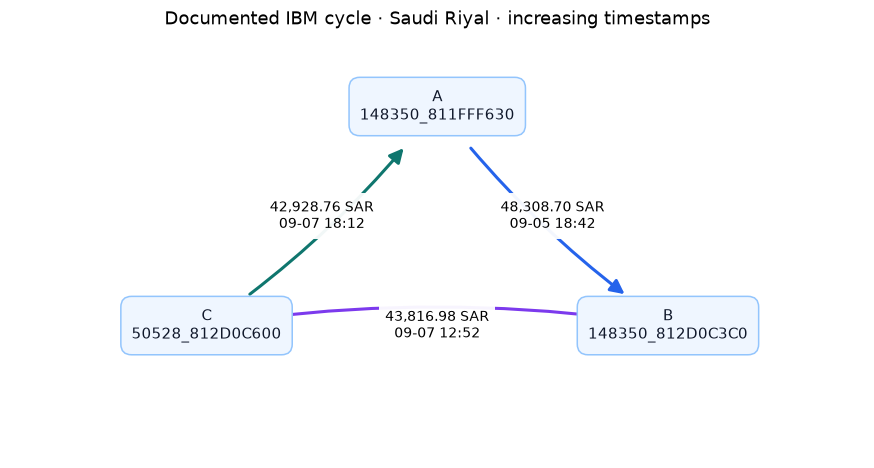

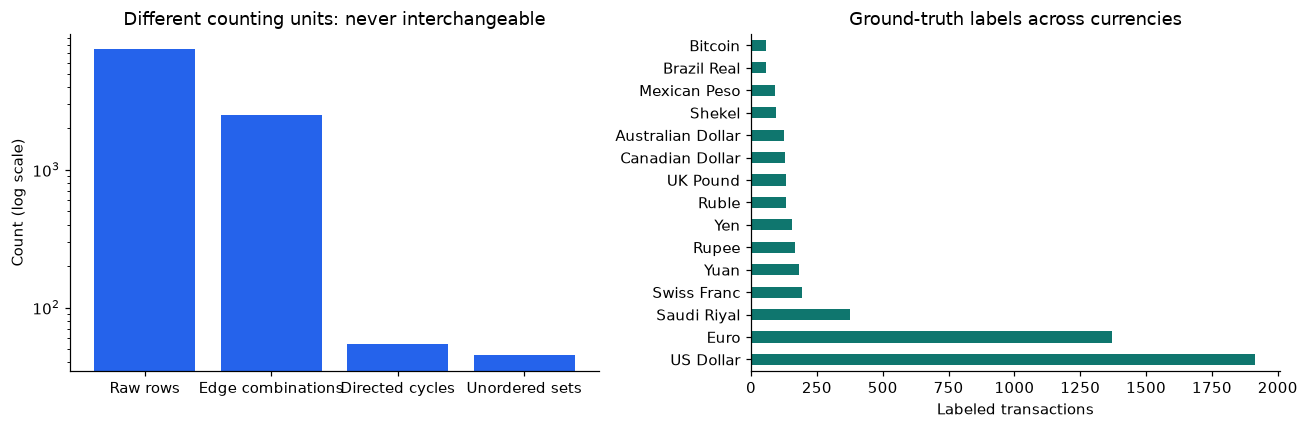

In [24]:
pattern_cycles = read_three_account_cycles(REPO_ROOT/'data/raw/ibm_aml/HI-Small_Patterns.txt')
payments = select_example(pattern_cycles,REPO_ROOT/'results/ibm_aml/fraud_directed_cycles.csv')
assert len(pattern_cycles) == 9
source_verification = []
for payment in payments:
    # Xác nhận từng cạnh ví dụ có trong input hiện tại; không suy đoán từ ảnh có sẵn.
    matches = ibm_loaded.edges.where(
        (F.col('src')==payment['src']) & (F.col('dst')==payment['dst']) &
        (F.col('timestamp')==F.lit(payment['timestamp'])) &
        (F.col('amount')==float(payment['amount'])) &
        (F.col('payment_currency')==payment['payment_currency']) & (F.col('isFraud')==1)).count()
    assert matches >= 1, payment
    source_verification.append({**payment,'matching_input_rows':matches})
display(pd.DataFrame(source_verification))
nodes = {letter:letter+'\n'+payment['src'] for letter,payment in zip('ABC',payments)}
edges = [(letter,'ABC'[(i+1)%3],f"{p['amount']:,.2f} SAR\n{p['timestamp']:%m-%d %H:%M}")
         for i,(letter,p) in enumerate(zip('ABC',payments))]
draw_graph(nodes,edges,'Documented IBM cycle · Saudi Riyal · increasing timestamps',
           colors=['#2563eb','#7c3aed','#0f766e'])
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(['Raw rows','Edge combinations','Directed cycles','Unordered sets'],
    [raw_cycle_count,transaction_combinations,directed_count,unordered_sets],color='#2563eb')
axes[0].set(yscale='log',ylabel='Count (log scale)',title='Different counting units: never interchangeable')
fraud_currencies.plot.barh(x='payment_currency',y='fraud_edges',ax=axes[1],legend=False,color='#0f766e')
axes[1].set(xlabel='Labeled transactions',ylabel='',title='Ground-truth labels across currencies')
plt.tight_layout()
plt.show()
fraud_matches.unpersist()
fraud_edges.unpersist()
directed.unpersist()
ibm.vertices.unpersist()
ibm.edges.unpersist()
spark.catalog.clearCache()
checks_passed['IBM documented cycle: source, time order and original currency'] = True


## 6 · Review và final Task 4 IBM

LPA cập nhật nhãn theo nhãn phổ biến trong lân cận:

$$L_v^{(t+1)}\in\operatorname{argmax}_{\ell}\sum_{u\in N(v)}\mathbf1[L_u^{(t)}=\ell].$$

Production dùng GraphFrames/GraphX `labelPropagation(maxIter=5)`. Chỉ đưa topology `id/src/dst` vào thuật toán rồi join lại metadata; giữ đa cạnh/self-loop của input. **Fraud/amount không tham gia bỏ phiếu**, chỉ dùng mô tả sau LPA. Label số có thể đổi giữa các lần chạy.

| Tiêu chí review | Kiểm tra |
|---|---|
| Checkpoint | `setCheckpointDir` trước LPA |
| Coverage | Mỗi account đúng một lần; không thiếu/thừa ID; label nguyên, không null |
| Metadata | bank_id/balance khớp input; balance IBM là placeholder |
| Profile | Đủ mọi community; members/banks/fraud/internal edges khớp input |
| Top 50 | Chỉ là view, không thay bảng đầy đủ |
| Amount | Group theo label **và payment_currency**, không cộng các loại tiền |
| Stability | So thành viên sau canonicalization, không so số label |

Hoàng phụ trách LPA; các cell tiếp theo chứa đầy đủ code đã được Khánh review/sửa và checker độc lập.


In [25]:
DEFAULT_CHECKPOINT_DIR = Path(runtime_temp.name)/'lpa_default'
COMMUNITIES_FILENAME = 'communities.csv'
COMMUNITY_SUMMARY_FILENAME = 'community_summary.csv'
COMMUNITY_SUMMARY_ALL_FILENAME = 'community_summary_all.csv'
COMMUNITY_AMOUNTS_FILENAME = 'community_amounts_by_currency.csv'


In [26]:
# LPA production đầy đủ: checkpoint, topology projection, labels join và cache.
# Production: src/ibm_aml/community_detection.py

def run_lpa(graph: GraphFrame, spark, max_iter: int = 5, checkpoint_dir: Path = DEFAULT_CHECKPOINT_DIR):
    """
    Thực thi Label Propagation Algorithm (LPA) trên IBM AML graph.
    """
    if max_iter <= 0:
        raise ValueError("max_iter must be > 0")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    spark.sparkContext.setCheckpointDir(str(checkpoint_dir.resolve()))

    print(f"\n[*] Đang thực thi LPA trên IBM AML (maxIter={max_iter}) với checkpoint tại: {checkpoint_dir} ...")
    # LPA voting uses topology. Keep all parallel/self-loop edges, but avoid
    # carrying transaction attributes and vertex metadata through GraphX.
    topology = GraphFrame(graph.vertices.select("id"), graph.edges.select("src", "dst"))
    labels = topology.labelPropagation(maxIter=max_iter)
    lpa_result = graph.vertices.join(labels.select("id", "label"), on="id", how="inner")

    lpa_result.cache()
    total_labeled = lpa_result.count()
    labels.unpersist()
    print(f"[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: {total_labeled:,}")

    return lpa_result


In [27]:
# Community profiling đầy đủ, không cộng amount khác đơn vị vào một tổng chung.
# Production: src/ibm_aml/community_detection.py

def analyze_communities(lpa_vertices, graph: GraphFrame, top_n: int = 15):
    """
    Phân tích đặc trưng cộng đồng trong dữ liệu ngân hàng IBM AML:
      - Kích thước cộng đồng và số ngân hàng tham gia (bank diversity).
      - Tỷ lệ giao dịch nội bộ cộng đồng vs liên cộng đồng.
      - Phân bổ giao dịch rửa tiền (Is Laundering / isFraud).
    """
    print("\n=== [Task 4] Phân tích Thống kê Cộng đồng IBM AML ===")

    # Kiểm tra cột có sẵn trong vertices
    has_bank = "bank_id" in lpa_vertices.columns

    agg_exprs = [F.count("*").alias("member_count")]
    if has_bank:
        agg_exprs.append(F.countDistinct("bank_id").alias("unique_banks_count"))
    if "balance" in lpa_vertices.columns:
        agg_exprs.append(F.round(F.avg("balance"), 2).alias("avg_balance"))

    community_sizes = (
        lpa_vertices
        .groupBy("label")
        .agg(*agg_exprs)
        .orderBy(F.desc("member_count"), F.asc("label"))
    )

    total_communities = community_sizes.count()
    if total_communities == 0:
        raise ValueError("Cannot analyze an empty IBM graph")
    singleton_count = community_sizes.filter(F.col("member_count") == 1).count()
    multi_member_count = total_communities - singleton_count

    print(f"  Tổng số cộng đồng phát hiện: {total_communities:,}")
    print(f"  Số cộng đồng đơn lẻ (Singletons - size=1): {singleton_count:,} ({singleton_count / total_communities * 100:.1f}%)")
    print(f"  Số cộng đồng có từ 2 thành viên trở lên:  {multi_member_count:,} ({multi_member_count / total_communities * 100:.1f}%)")

    # B. Gán nhãn cộng đồng vào Edges
    edges = graph.edges
    v_labels = lpa_vertices.select(F.col("id"), F.col("label"))

    edges_with_labels = (
        edges
        .join(v_labels.withColumnRenamed("id", "src").withColumnRenamed("label", "src_label"), on="src", how="inner")
        .join(v_labels.withColumnRenamed("id", "dst").withColumnRenamed("label", "dst_label"), on="dst", how="inner")
    )
    edges_with_labels.cache()

    total_edges = edges_with_labels.count()
    if total_edges == 0:
        raise ValueError("Cannot analyze an IBM graph without transactions")
    internal_edges = edges_with_labels.filter(F.col("src_label") == F.col("dst_label"))
    internal_count = internal_edges.count()
    cross_count = total_edges - internal_count

    print(f"\n  Phân tích ranh giới dòng tiền:")
    print(f"    Giao dịch nội bộ cộng đồng: {internal_count:,} ({internal_count / total_edges * 100:.1f}%)")
    print(f"    Giao dịch liên cộng đồng:    {cross_count:,} ({cross_count / total_edges * 100:.1f}%)")

    # C. Thống kê rửa tiền theo cộng đồng nguồn (src_label)
    fraud_col = "isFraud" if "isFraud" in edges.columns else "isLaundering"

    fraud_stats = (
        edges_with_labels
        .groupBy("src_label")
        .agg(
            F.count("*").alias("total_tx_count"),
            F.sum(fraud_col).alias("laundering_tx_count"),
            F.sum(F.when(F.col("src_label") == F.col("dst_label"), 1).otherwise(0)).alias("internal_tx_count"),
            F.sum(F.when((F.col("src_label") == F.col("dst_label")) & (F.col(fraud_col) == 1), 1).otherwise(0)).alias("internal_laundering_count"),
        )
        .withColumnRenamed("src_label", "label")
    )

    summary_df = (
        community_sizes
        .join(fraud_stats, on="label", how="left")
        .na.fill(0, subset=["total_tx_count", "laundering_tx_count", "internal_tx_count", "internal_laundering_count"])
        .withColumn(
            "laundering_rate",
            F.round(F.col("laundering_tx_count") / F.when(F.col("total_tx_count") == 0, 1).otherwise(F.col("total_tx_count")), 4)
        )
        .orderBy(F.desc("member_count"), F.asc("label"))
    )

    print(f"\n=== Top {top_n} Cộng đồng IBM AML lớn nhất ===")
    summary_df.show(top_n, truncate=False)

    # Đánh giá cụm rửa tiền
    laundering_hotspots = summary_df.filter(F.col("laundering_tx_count") > 0).orderBy(F.desc("laundering_tx_count"))
    laundering_community_count = laundering_hotspots.count()
    print(f"\n  Số lượng cộng đồng chứa giao dịch rửa tiền (Laundering): {laundering_community_count:,}")
    if laundering_community_count > 0:
        print("  Top 5 cộng đồng tập trung nhiều giao dịch rửa tiền nhất:")
        laundering_hotspots.show(5, truncate=False)

    return community_sizes, summary_df


### Chạy full IBM

Không `toPandas()` toàn bộ graph; chỉ lấy bảng nhỏ để trình bày. Bảng amount tách riêng loại tiền. Số community không bị hardcode làm điều kiện PASS vì LPA có thể khác giữa các lần/môi trường chạy.


In [28]:
ibm_full = load_graph(spark,str(REPO_ROOT/'data/processed/ibm_aml'))
full_labels = run_lpa(ibm_full,spark,max_iter=5,checkpoint_dir=Path(runtime_temp.name)/'full')
full_sizes,full_summary = analyze_communities(full_labels,ibm_full,top_n=8)
full_summary = full_summary.cache()
full_overview = full_summary.orderBy(F.desc('member_count'),F.asc('label')).limit(50)
full_amounts = (ibm_full.edges.join(full_labels.select(F.col('id').alias('src'),'label'),'src')
    .groupBy('label','payment_currency').agg(F.count('*').alias('total_tx_count'),
                                           F.sum('amount').alias('total_tx_amount'))).cache()
display(full_overview.limit(8).toPandas())
display(full_amounts.where(F.col('payment_currency')=='US Dollar').orderBy(
    F.desc('total_tx_amount')).limit(8).toPandas())



[*] Đang thực thi LPA trên IBM AML (maxIter=5) với checkpoint tại: C:\Users\ADMIN\AppData\Local\Temp\graphguard-khanh-78_nw4pe\full ...
[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: 518,581

=== [Task 4] Phân tích Thống kê Cộng đồng IBM AML ===
  Tổng số cộng đồng phát hiện: 314,531
  Số cộng đồng đơn lẻ (Singletons - size=1): 207,828 (66.1%)
  Số cộng đồng có từ 2 thành viên trở lên:  106,703 (33.9%)

  Phân tích ranh giới dòng tiền:
    Giao dịch nội bộ cộng đồng: 852,853 (16.8%)
    Giao dịch liên cộng đồng:    4,225,492 (83.2%)

=== Top 8 Cộng đồng IBM AML lớn nhất ===
+-----------+------------+------------------+-----------+--------------+-------------------+-----------------+-------------------------+---------------+
|label      |member_count|unique_banks_count|avg_balance|total_tx_count|laundering_tx_count|internal_tx_count|internal_laundering_count|laundering_rate|
+-----------+------------+------------------+-----------+--------------+-------------------+---------------

,label,member_count,unique_banks_count,avg_balance,total_tx_count,laundering_tx_count,internal_tx_count,internal_laundering_count,laundering_rate
0,34359801819,6973,1267,0.0,42492,67,8340,0,0.0016
1,8589997895,4631,820,0.0,31455,45,5765,1,0.0014
2,17179885612,2509,1278,0.0,181065,252,2576,0,0.0014
3,8589976292,1527,775,0.0,111115,172,1561,1,0.0015
4,62824,986,190,0.0,6689,2,1229,0,0.0003
5,62823,840,139,0.0,5967,6,1148,1,0.0010
6,34359801820,763,150,0.0,4541,15,1038,0,0.0033
7,25769866961,725,123,0.0,4980,3,845,0,0.0006


,label,payment_currency,total_tx_count,total_tx_amount
0,17179885612,US Dollar,180972,5.761369e+10
1,8589956008,US Dollar,80,1.978677e+10
2,60129564378,US Dollar,4,1.662837e+10
3,34359801819,US Dollar,42236,1.614028e+10
4,18296,US Dollar,102,1.380892e+10
5,26863,US Dollar,10,1.379447e+10
6,60129568318,US Dollar,6,7.976449e+09
7,38076,US Dollar,6,7.027710e+09


### Checker độc lập: tính lại từ graph và assignments

Checker so key hai chiều, numeric hữu hạn, count chính xác và tolerance float, summary đầy đủ, top 50, và amount theo currency. `verify_community_frames` là hàm production dùng chung với checker CSV, nên notebook không cần ghi file trung gian.


In [29]:
# Guard key/numeric và đối chiếu thống kê trước khi công nhận kết quả.
# Production: src/ibm_aml/verify_communities.py

def require(condition, message):
    if not condition:
        raise ValueError(message)

def numeric(frame, names: list[str], integral: bool = True):
    invalid_fields = []
    for name in names:
        parsed = F.col(name).cast("long" if integral else "double")
        invalid = parsed.isNull()
        if integral:
            invalid = invalid | ~F.col(name).rlike(r"^-?[0-9]+$")
        else:
            invalid = invalid | F.isnan(parsed) | (F.abs(parsed) == float("inf"))
        invalid_fields.append(invalid)
    require(frame.where(reduce(lambda a, b: a | b, invalid_fields)).limit(1).count() == 0,
            f"Invalid numeric values in {names}")
    for name in names:
        parsed = F.col(name).cast("long" if integral else "double")
        frame = frame.withColumn(name, parsed)
    return frame

def unique_keys(frame, keys: list[str], name: str):
    require(frame.where(reduce(lambda a, b: a | b,
            [F.col(key).isNull() | (F.trim(F.col(key)) == "") for key in keys])).limit(1).count() == 0,
            f"{name}: null/blank keys")
    require(frame.groupBy(*keys).count().where(F.col("count") != 1).limit(1).count() == 0,
            f"{name}: duplicate keys")

def same_keys(actual, expected, keys: list[str], name: str):
    missing = expected.select(*keys).join(actual.select(*keys), keys, "left_anti").count()
    extra = actual.select(*keys).join(expected.select(*keys), keys, "left_anti").count()
    require(missing == 0 and extra == 0,
            f"{name}: incomplete or foreign keys (missing={missing}, extra={extra}); top-50 is not a full summary")

def compare_values(actual, expected, keys: list[str], counts: list[str], floats: list[str], name: str):
    unique_keys(actual, keys, name)
    same_keys(actual, expected, keys, name)
    actual = numeric(actual, counts)
    actual = numeric(actual, floats, integral=False)
    renamed = expected.select(*keys, *[F.col(col).alias("expected_" + col) for col in counts + floats])
    joined = actual.join(renamed, keys, "inner")
    errors = [F.col(col) != F.col("expected_" + col) for col in counts]
    for col in floats:
        tolerance = F.greatest(F.lit(1e-8), F.abs(F.col("expected_" + col)) * F.lit(1e-12))
        errors.append(F.abs(F.col(col) - F.col("expected_" + col)) > tolerance)
    require(joined.where(reduce(lambda a, b: a | b, errors)).limit(1).count() == 0,
            f"{name}: statistics differ from input graph and assignments")


In [30]:
# Checker DataFrame production đầy đủ, tính lại mọi chỉ số từ input graph.
# Production: src/ibm_aml/verify_communities.py

def verify_community_frames(graph, assignments, summary, overview, amounts) -> dict:
    """Reconcile in-memory tables with the graph, without exporting files.

    Both the presentation notebook and the CSV delivery checker use these
    same checks. No labels or summary statistics are inferred from filenames.
    """
    cached = []
    try:
        vertices = graph.vertices.select("id", "bank_id", "balance").cache()
        edges = graph.edges.select("src", "dst", "isFraud", "amount", "payment_currency").cache()
        cached.extend([vertices, edges])
        unique_keys(vertices, ["id"], "input vertices")
        vertex_count, edge_count = vertices.count(), edges.count()
        require(vertex_count > 0 and edge_count > 0, "Empty input graph")
        require(vertices.where(F.col("bank_id").isNull() | (F.trim(F.col("bank_id")) == "")
                | F.col("balance").isNull() | F.isnan(F.col("balance"))
                | (F.abs(F.col("balance")) == float("inf"))).limit(1).count() == 0,
                "Input bank IDs/balances must be present and finite")
        require(edges.where(F.col("payment_currency").isNull() | (F.trim(F.col("payment_currency")) == "")
                | F.col("amount").isNull() | F.isnan(F.col("amount"))
                | (F.abs(F.col("amount")) == float("inf"))).limit(1).count() == 0,
                "Input amounts/currencies must be present and finite")
        require(edges.where(F.col("isFraud").isNull() | ~F.col("isFraud").isin(0, 1)).limit(1).count() == 0,
                "Input fraud labels must be 0/1")

        unique_keys(assignments, ["id"], "assignments")
        assignments = numeric(assignments, ["label"]).cache()
        cached.append(assignments)
        same_keys(assignments, vertices, ["id"], "assignments")
        print(f"[PASS] Exact account coverage and non-null integer labels: {vertex_count:,}")
        if "bank_id" in assignments.columns:
            require(assignments.join(vertices.select("id", F.col("bank_id").alias("expected_bank")), "id")
                    .where(~F.col("bank_id").eqNullSafe(F.col("expected_bank"))).limit(1).count() == 0,
                    "Exported bank_id does not match the input account")

        members = assignments.select("id", "label").join(vertices, "id")
        sizes = members.groupBy("label").agg(
            F.count("*").alias("member_count"), F.countDistinct("bank_id").alias("unique_banks_count"),
            F.round(F.avg("balance"), 2).alias("avg_balance"))
        source_labels = assignments.select(F.col("id").alias("src"), F.col("label").alias("src_label"))
        dest_labels = assignments.select(F.col("id").alias("dst"), F.col("label").alias("dst_label"))
        labeled = edges.join(source_labels, "src", "left").join(dest_labels, "dst", "left").cache()
        cached.append(labeled)
        require(labeled.where(F.col("src_label").isNull() | F.col("dst_label").isNull()).limit(1).count() == 0,
                "Input graph has dangling edges")
        internal = F.col("src_label") == F.col("dst_label")
        statistics = labeled.groupBy("src_label").agg(
            F.count("*").alias("total_tx_count"), F.sum("isFraud").alias("laundering_tx_count"),
            F.sum(F.when(internal, 1).otherwise(0)).alias("internal_tx_count"),
            F.sum(F.when(internal & (F.col("isFraud") == 1), 1).otherwise(0)).alias("internal_laundering_count"),
        ).withColumnRenamed("src_label", "label")
        counts = ["member_count", "unique_banks_count", "total_tx_count", "laundering_tx_count",
                  "internal_tx_count", "internal_laundering_count"]
        expected = sizes.join(statistics, "label", "left").fillna(0, subset=counts[2:])
        expected = expected.withColumn("laundering_rate", F.round(
            F.col("laundering_tx_count") / F.when(F.col("total_tx_count") == 0, 1)
            .otherwise(F.col("total_tx_count")), 4)).cache()
        cached.append(expected)
        summary = numeric(summary, ["label"])
        compare_values(summary, expected, ["label"], counts, ["avg_balance", "laundering_rate"], "summary")
        require("total_tx_amount" not in summary.columns,
                "Ambiguous total_tx_amount in community summary; amounts must be separated by payment_currency")
        print("[PASS] Complete community sizes, banks, balances, transaction/fraud/internal counts and rates")

        # The top-50 display file remains a view; verify every displayed row.
        overview = numeric(overview, ["label"])
        top_expected = expected.orderBy(F.desc("member_count"), F.asc("label")).limit(50)
        compare_values(overview, top_expected, ["label"], counts,
                       ["avg_balance", "laundering_rate"], "top-50 overview")

        amounts_expected = labeled.groupBy("src_label", "payment_currency").agg(
            F.count("*").alias("total_tx_count"), F.sum("amount").alias("total_tx_amount")
        ).withColumnRenamed("src_label", "label")
        amounts = numeric(amounts, ["label"])
        compare_values(amounts, amounts_expected, ["label", "payment_currency"], ["total_tx_count"],
                       ["total_tx_amount"], "amounts by currency")
        totals = labeled.agg(F.sum("isFraud").alias("fraud"),
                            F.sum(F.when(internal, 1).otherwise(0)).alias("internal")).first()
        return {"vertices": vertex_count, "assigned_vertices": assignments.count(),
                "edges": edge_count, "communities": expected.count(), "summary_rows": summary.count(),
                "internal_edges": totals["internal"], "cross_edges": edge_count - totals["internal"],
                "fraud_edges": totals["fraud"], "amount_currency_rows": amounts.count()}
    finally:
        for frame in reversed(cached):
            frame.unpersist()


In [31]:
full_lpa_metrics = verify_community_frames(ibm_full,full_labels,full_summary,full_overview,full_amounts)
assert full_lpa_metrics['assigned_vertices'] == full_lpa_metrics['vertices'] == 518_581
assert full_lpa_metrics['edges'] == 5_078_345
assert full_lpa_metrics['internal_edges']+full_lpa_metrics['cross_edges'] == full_lpa_metrics['edges']
display(pd.DataFrame([full_lpa_metrics]))
checks_passed['Task 4 IBM full: independent complete reconciliation'] = True


[PASS] Exact account coverage and non-null integer labels: 518,581
[PASS] Complete community sizes, banks, balances, transaction/fraud/internal counts and rates


,vertices,assigned_vertices,edges,communities,summary_rows,internal_edges,cross_edges,fraud_edges,amount_currency_rows
0,518581,518581,5078345,314531,314531,852853,4225492,5177,314305


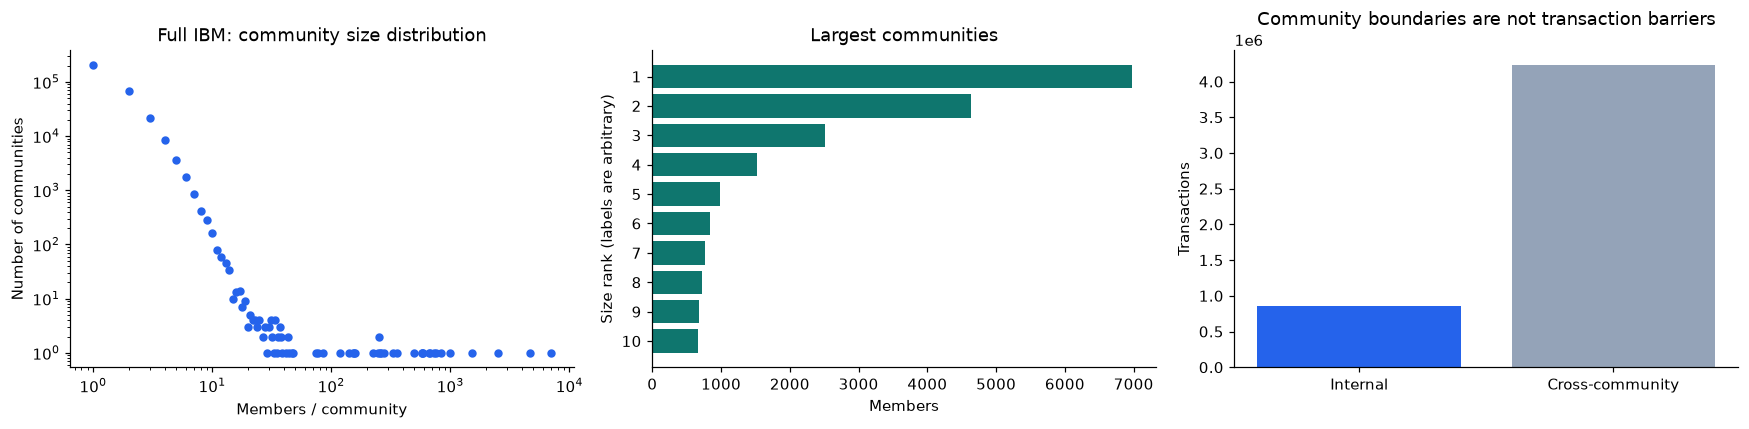

Internal edges: 16.79%
Fraud labels trong community là profile sau LPA, không chứng minh một fraud ring.


In [32]:
# Đồ thị được tính từ chính lần full LPA ở trên.
size_distribution = full_summary.groupBy('member_count').count().orderBy('member_count').toPandas()
top_communities = full_overview.limit(10).toPandas()
fig,axes = plt.subplots(1,3,figsize=(16,4))
axes[0].scatter(size_distribution.member_count,size_distribution['count'],color='#2563eb',s=20)
axes[0].set(xscale='log',yscale='log',xlabel='Members / community',ylabel='Number of communities',
            title='Full IBM: community size distribution')
axes[1].barh([str(i+1) for i in range(len(top_communities))],top_communities.member_count,color='#0f766e')
axes[1].invert_yaxis()
axes[1].set(xlabel='Members',ylabel='Size rank (labels are arbitrary)',title='Largest communities')
axes[2].bar(['Internal','Cross-community'],[full_lpa_metrics['internal_edges'],
    full_lpa_metrics['cross_edges']],color=['#2563eb','#94a3b8'])
axes[2].set(ylabel='Transactions',title='Community boundaries are not transaction barriers')
plt.tight_layout()
plt.show()
print(f"Internal edges: {full_lpa_metrics['internal_edges']/full_lpa_metrics['edges']:.2%}")
print('Fraud labels trong community là profile sau LPA, không chứng minh một fraud ring.')
full_labels.unpersist()
full_summary.unpersist()
full_amounts.unpersist()
spark.catalog.clearCache()


### Hai lần sample: so thành viên, bỏ qua số label

Đại diện mỗi community bằng ID tài khoản nhỏ nhất rồi so account→anchor. `same_partition=False` là quan sát stability, không tự động là lỗi. Hai lần giống nhau cũng không chứng minh luôn deterministic. Kiểm tra sample này tách biệt kết quả full ở trên.


In [33]:
# Canonicalize theo min account ID; so thành viên thay vì số label.
# Production: src/ibm_aml/verify_communities.py

def compare_partition_frames(current, previous) -> dict:
    """Compare membership using each community's minimum account ID, ignoring label numbers."""
    frames = []
    for assignments in (current, previous):
        frame = numeric(assignments, ["label"])
        unique_keys(frame, ["id"], "partition")
        canonical = frame.groupBy("label").agg(F.min("id").alias("community_anchor"))
        frames.append(frame.join(canonical, "label").select("id", "community_anchor"))
    same_keys(frames[0], frames[1], ["id"], "partition account set")
    joined = frames[0].join(frames[1].withColumnRenamed("community_anchor", "previous_anchor"), "id")
    changed = joined.where(F.col("community_anchor") != F.col("previous_anchor")).count()
    return {"same_partition": changed == 0, "accounts_with_changed_canonical_community": changed,
            "accounts": joined.count(), "interpretation": "observed comparison; differences do not invalidate LPA"}


In [34]:
ibm_sample = load_graph(spark,str(REPO_ROOT/'data/processed/sample/ibm_aml'))
sample_labels_1 = run_lpa(ibm_sample,spark,max_iter=5,checkpoint_dir=Path(runtime_temp.name)/'sample_1')
sample_labels_2 = run_lpa(ibm_sample,spark,max_iter=5,checkpoint_dir=Path(runtime_temp.name)/'sample_2')
for assignments in (sample_labels_1,sample_labels_2):
    unique_keys(assignments,['id'],'sample assignments')
    same_keys(assignments,ibm_sample.vertices,['id'],'sample coverage')
    numeric(assignments,['label'])
stability = compare_partition_frames(sample_labels_2,sample_labels_1)
display(pd.DataFrame([stability]))
sample_labels_1.unpersist()
sample_labels_2.unpersist()
spark.catalog.clearCache()
checks_passed['Task 4 IBM: two live sample runs and membership comparison'] = True



[*] Đang thực thi LPA trên IBM AML (maxIter=5) với checkpoint tại: C:\Users\ADMIN\AppData\Local\Temp\graphguard-khanh-78_nw4pe\sample_1 ...
[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: 119,043

[*] Đang thực thi LPA trên IBM AML (maxIter=5) với checkpoint tại: C:\Users\ADMIN\AppData\Local\Temp\graphguard-khanh-78_nw4pe\sample_2 ...
[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: 119,043


,same_partition,accounts_with_changed_canonical_community,accounts,interpretation
0,True,0,119043,observed comparison; differences do not invali...


### Các phản ví dụ checker phải từ chối

Account trùng/thiếu, label null/không nguyên, amount NaN và cột amount tổng hợp không tách currency. Kiểm tra trong bộ nhớ, không tạo test CSV.


In [35]:
def expect_rejection(label,operation):
    try:
        operation()
    except ValueError as error:
        return {'case':label,'status':'PASS: rejected','reason':str(error)}
    raise AssertionError('Checker không từ chối: '+label)

# Phản ví dụ currency đi qua chính checker đầy đủ, không chỉ qua một assert riêng.
review_vertices = spark.sql("SELECT * FROM VALUES ('A','1',0.0),('B','1',0.0) AS v(id,bank_id,balance)")
review_edges = spark.sql("SELECT 'A' AS src,'B' AS dst,0 AS isFraud,10.0 AS amount,'US Dollar' AS payment_currency")
review_graph = GraphFrame(review_vertices,review_edges)
review_assignments = review_vertices.select('id').withColumn('label',F.lit(1).cast('long'))
review_summary = spark.sql("SELECT CAST(1 AS BIGINT) AS label,2 AS member_count,1 AS unique_banks_count,"
    "0.0 AS avg_balance,1 AS total_tx_count,0 AS laundering_tx_count,1 AS internal_tx_count,"
    "0 AS internal_laundering_count,0.0 AS laundering_rate")
review_amounts = spark.sql("SELECT CAST(1 AS BIGINT) AS label,'US Dollar' AS payment_currency,"
    "1 AS total_tx_count,10.0 AS total_tx_amount")

one = spark.sql("SELECT 'A' AS id,'1' AS label")
two = spark.sql("SELECT * FROM VALUES ('A','1'),('B','2') AS t(id,label)")
rejections = [
    expect_rejection('duplicate account',lambda:unique_keys(one.unionByName(one),['id'],'assignments')),
    expect_rejection('missing account',lambda:same_keys(one,two,['id'],'assignments')),
    expect_rejection('null label',lambda:numeric(spark.sql("SELECT CAST(NULL AS STRING) AS label"),['label'])),
    expect_rejection('fractional label',lambda:numeric(spark.sql("SELECT '1.5' AS label"),['label'])),
    expect_rejection('NaN amount',lambda:numeric(spark.sql("SELECT 'NaN' AS amount"),['amount'],integral=False)),
    expect_rejection('mixed-currency summary field',lambda:verify_community_frames(
        review_graph,review_assignments,review_summary.withColumn('total_tx_amount',F.lit(10.0)),
        review_summary,review_amounts)),
]
assert 'payment_currency' in rejections[-1]['reason']
display(pd.DataFrame(rejections))
checks_passed['Checker rejects malformed keys, labels and amounts'] = True


[PASS] Exact account coverage and non-null integer labels: 2


,case,status,reason
0,duplicate account,PASS: rejected,assignments: duplicate keys
1,missing account,PASS: rejected,assignments: incomplete or foreign keys (missi...
2,null label,PASS: rejected,Invalid numeric values in ['label']
3,fractional label,PASS: rejected,Invalid numeric values in ['label']
4,NaN amount,PASS: rejected,Invalid numeric values in ['amount']
5,mixed-currency summary field,PASS: rejected,Ambiguous total_tx_amount in community summary...


### Hàm xuất CSV production — đầy đủ để đọc, không gọi trong notebook

CLI bàn giao assignments, top 50, **toàn bộ** summary và amount theo currency. Cell dưới chỉ định nghĩa nguyên hàm export để thầy đọc được ngay; không gọi hàm này và không tạo các file CSV đó.


In [36]:
# Toàn bộ export production; chỉ định nghĩa để đọc, không ghi file từ notebook.
# Production: src/ibm_aml/community_detection.py

def export_results(lpa_vertices, summary_df, output_dir: Path, graph: GraphFrame | None = None):
    """Xuất các file CSV độc lập theo chuẩn UTF-8 BOM."""
    output_dir.mkdir(parents=True, exist_ok=True)

    communities_path = output_dir / COMMUNITIES_FILENAME
    summary_path = output_dir / COMMUNITY_SUMMARY_FILENAME

    print(f"\n=== [Task 4] Xuất kết quả bàn giao IBM AML ===")

    # 1. Xuất file communities.csv
    export_cols = ["id", "label"]
    if "bank_id" in lpa_vertices.columns:
        export_cols.insert(1, "bank_id")
    if "account_type" in lpa_vertices.columns:
        export_cols.append("account_type")

    pdf_communities = (
        lpa_vertices
        .select(*export_cols)
        .orderBy(F.asc("label"), F.asc("id"))
        .toPandas()
    )
    pdf_communities.to_csv(communities_path, index=False, encoding="utf-8-sig")
    print(f"  [OK] Đã ghi danh sách cộng đồng IBM AML: {communities_path} ({len(pdf_communities):,} accounts)")

    # 2. Xuất file community_summary.csv
    pdf_summary = summary_df.limit(50).toPandas()
    pdf_summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
    print(f"  [OK] Đã ghi bảng tổng hợp cộng đồng IBM AML: {summary_path} (Top {len(pdf_summary)} communities)")

    # Keep the top-50 report above, and export a complete table for reconciliation.
    def write_spark_csv(frame, path):
        with path.open("w", newline="", encoding="utf-8-sig") as stream:
            writer = csv.writer(stream, lineterminator="\n")
            writer.writerow(frame.columns)
            for row in frame.toLocalIterator():
                writer.writerow(list(row))

    write_spark_csv(summary_df, output_dir / COMMUNITY_SUMMARY_ALL_FILENAME)
    if graph is not None:
        labels = lpa_vertices.select(F.col("id").alias("src"), "label")
        amounts = (graph.edges.join(labels, on="src", how="inner")
                   .groupBy("label", "payment_currency")
                   .agg(F.count("*").alias("total_tx_count"),
                        F.sum("amount").alias("total_tx_amount"))
                   .orderBy("label", "payment_currency"))
        write_spark_csv(amounts, output_dir / COMMUNITY_AMOUNTS_FILENAME)
    print("  [OK] Đã ghi toàn bộ community summary và amount theo từng payment_currency")


## 7 · Đối chiếu source và nghiệm thu kỹ thuật

So AST của **mọi hàm production có trong notebook** với file Python tương ứng. Notebook không giấu code quan trọng sau import hoặc chỉ in tên file. Cell điều phối motif giữ query/điều kiện/cách đếm của production và thay việc ghi CSV/JSON bằng bảng/assert trong bộ nhớ. Windows/Spark là hạ tầng dùng chung.


In [37]:
notebook_document = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
visible_functions = {}
for cell in notebook_document['cells']:
    if cell['cell_type'] == 'code':
        for node in ast.parse(''.join(cell['source'])).body:
            if isinstance(node,ast.FunctionDef):
                visible_functions[node.name] = node
source_audit = []
for record in notebook_document['metadata']['graphguard_sources']:
    source = (REPO_ROOT/record['path']).read_text(encoding='utf-8')
    actual_functions = {n.name:n for n in ast.parse(source).body if isinstance(n,ast.FunctionDef)}
    for name in record['functions']:
        assert ast.dump(visible_functions[name],include_attributes=False) == ast.dump(
            actual_functions[name],include_attributes=False), f'Source drift: {record["path"]}:{name}'
    source_audit.append({'module':record['path'],'functions':', '.join(record['functions']),
                         'sha256':hashlib.sha256(source.encode('utf-8')).hexdigest(),'status':'MATCH'})
display(pd.DataFrame(source_audit))
checks_passed['All displayed production functions match repository AST'] = True


,module,functions,sha256,status
0,src/common/graph_utils.py,load_graph,cd47cd4aa66ba4ff3977b9d9650671d1b52d3b9391ede5...,MATCH
1,src/motif/toy_cycle.py,"build_toy_graph, find_three_node_cycles, cycle...",44caa76842030eb834f9e854fd7f8b18cd5aabf2498f47...,MATCH
2,src/ibm_aml/etl.py,"validate_csv_header, invalid_required_values, ...",2602afff5b9d4bf22101f6af3b460c3377add35ce0c1af...,MATCH
3,src/ibm_aml/etl.py,"build_ibm_vertices, sample_ibm_edges",2602afff5b9d4bf22101f6af3b460c3377add35ce0c1af...,MATCH
4,src/common/graph_utils.py,check_integrity,cd47cd4aa66ba4ff3977b9d9650671d1b52d3b9391ede5...,MATCH
5,tests/test_ibm_aml_etl.py,run_tests,6b7d4ab67c29e898f178e08bd783aae7974238149ea258...,MATCH
6,src/paysim/motif_finding.py,"find_relays, relay_rows",d6680cc1445accaba89d78af96ab82eb695148bbb52fb4...,MATCH
7,src/ibm_aml/motif_finding.py,"directed_account_cycles, find_usd_cycles",a84b05a55a5c7e6c43d916f0baf9b9437e34fb3a912ec6...,MATCH
8,src/ibm_aml/visualize.py,"read_three_account_cycles, select_example",0203b99ca86b358e3eea0a6ff4ce9f253c7bbeb24f877b...,MATCH
9,src/ibm_aml/community_detection.py,run_lpa,ddfd4c3cb584ed94b1b3e56232074e2dd9aff4e0e659d4...,MATCH


### Các kết luận cần trình bày đúng

- **Toy:** 3 raw matches là 3 phép xoay của 1 cycle.
- **PaySim:** full cycle = 0, 30 relay gồm 28 cặp thứ tự giờ rõ và 2 cặp cùng giờ; các cạnh ứng viên đều có nhãn 0.
- **IBM:** audit nhãn có 7.473 raw rows, 54 cycle có hướng, 2.491 tổ hợp giao dịch, 45 bộ ba không xét chiều. Query USD không dùng nhãn có 0 kết quả.
- **LPA:** full được kiểm chứng độc lập; sample hai lần chỉ phục vụ quan sát stability sample. Community không phải kết luận rửa tiền.
- **Review/final:** PASS tự động không thay comment review của Phương/Hoàng hay duyệt final của Tuệ Minh. Notebook không sửa trạng thái CSV phân công.

**Cách thuyết trình:** giới thiệu rule → chỉ đúng hàm → đọc output → giải thích hình → nêu giới hạn. Khi thầy hỏi tính đúng, mở assert và checker độc lập ngay phía trên.


In [38]:
assert all(checks_passed.values())
finished_at = datetime.now(timezone.utc)
display(pd.DataFrame([{'check':name,'status':'PASS'} for name in checks_passed]))
display(pd.DataFrame([{'started_utc':started_at.isoformat(),'finished_utc':finished_at.isoformat(),
    'elapsed_seconds':round(time.perf_counter()-started_clock,1),'pay_scope':'full','ibm_scope':'full',
    'stability_scope':'sample, 2 live runs','human_review_approval':'not certified by automated checks',**runtime}]))
# Dừng JVM trước khi dọn checkpoint tạm.
spark.catalog.clearCache()
spark.stop()
runtime_temp.cleanup()
print('PASS — toàn bộ notebook đã chạy; bảng và hình nằm trong output notebook.')


,check,status
0,Windows Python 3.12 / JDK 17 / dependencies,PASS
1,Toy graph.find: 3 rotations / 1 cycle,PASS
2,"PageRank: leakage, damping, mass and worked ex...",PASS
3,"IBM ETL: raw contract, integrity and exact Par...",PASS
4,Motif adversarial graphs and relay boundaries,PASS
5,Task 3 PaySim full + exact delivered CSV,PASS
6,"Task 3 IBM full: rotations, multiplicity, curr...",PASS
7,"IBM documented cycle: source, time order and o...",PASS
8,Task 4 IBM full: independent complete reconcil...,PASS
9,Task 4 IBM: two live sample runs and membershi...,PASS


,started_utc,finished_utc,elapsed_seconds,pay_scope,ibm_scope,stability_scope,human_review_approval,system,python,spark,graphframes,java,master,driver_memory,session_timezone
0,2026-10-18T13:00:28.133395+00:00,2026-10-18T13:06:29.274564+00:00,361.1,full,full,"sample, 2 live runs",not certified by automated checks,Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],8g,Asia/Saigon


PASS — toàn bộ notebook đã chạy; bảng và hình nằm trong output notebook.
